# Software Engineering for AI Developers: System Design Fundamentals

> **Who is this for:** you can build an app that works on your laptop and now want to know how systems serve millions of users without falling over, or you are preparing for a **system design interview**. Also for university students revising *distributed systems* basics.
>
> **What you will learn:**
> - a repeatable **method** for design problems: requirements, back-of-the-envelope estimation (worked in code), API, data model, high-level design, deep dives, bottlenecks
> - **scalability**: vertical vs. horizontal, stateless services, **load-balancing algorithms** (round robin, least connections, power of two choices, **consistent hashing**), all simulated
> - **caching**: cache-aside, write-through, write-back, eviction, TTL, **cache stampede**, CDNs; **LRU vs. LFU** implemented and compared on a Zipf workload
> - **databases at scale**: replication and replication lag, quorums, read replicas, **sharding** and hot keys, indexes, SQL vs. NoSQL, a precise **CAP / PACELC** recap
> - **asynchronous processing**: queues, pub/sub, delivery guarantees, **idempotency keys**, a **dead-letter queue** (simulated with `queue.Queue`)
> - **resilience**: five **rate-limiting algorithms** implemented and compared, a **circuit breaker**, retries with exponential backoff and jitter, timeouts, bulkheads
> - **observability**: logs, metrics, traces, percentiles, **SLIs/SLOs/error budgets** and burn-rate alerts, the "nines" of availability
> - five compact **case studies**: URL shortener, chat system, news feed, rate-limiter service and an **LLM chat app** (streaming, a GPU queue, caching, cost per request), plus an **interview checklist**
>
> **Prerequisites:** [Python basics](../01_Python/01_basic.ipynb), [Python production patterns](../01_Python/02_industrial.ipynb) (threads, dataclasses), [SQL fundamentals](../13_Databases/01_sql/01_sql_fundamentals.ipynb). Helpful: [DBMS fundamentals](../13_Databases/00_dbms_fundamentals/01_dbms_introduction_and_architecture.ipynb), [Concurrency and async](05_concurrency_and_async.ipynb), [Computer networks for AI apps](07_computer_networks_for_ai_apps.ipynb), [FastAPI intro](../12_FastAPI/01_fastapi_intro.ipynb).
>
> **Time needed:** 3–4 hours (reading + running + practice problems).
>
> **Runs on:** CPU, no API key, no network; about half a minute.
>
> **Optional track:** this notebook is part of the *university-level fundamentals track*; recommended for BS/MS AI students and interview prep.

## Explained simply

System design is planning how a big app keeps working when millions of people use it at the same time. One computer can only do so much, so we split the work across many computers and make them cooperate. Most of the tricks are about three things: sharing the work fairly, remembering answers so we do not redo slow work, and coping calmly when something breaks. Before building anything, engineers do quick "back-of-the-envelope" maths to see how big the problem really is.

- **Supermarket checkouts:** when the queues get long, the shop opens more tills (*horizontal scaling*) and a staff member sends each customer to the shortest queue (*load balancing*).
- **Your school bag vs. your locker:** you keep the books you use most in your bag so you do not walk to the locker every lesson. That is a *cache*.
- **A restaurant kitchen:** waiters pin order tickets on a rail and cooks take them one by one, so a sudden rush does not overwhelm anyone. That is a *message queue*.

**A tiny example.** A school timetable app has 2,000 students who each open it 5 times a day: 10,000 requests a day, divided by 86,400 seconds in a day, is about 0.12 requests per second. A laptop can handle that. If 10 million people did the same, it would be 50 million requests a day, about 580 per second on average and maybe 1,700 per second at the busiest time, so now you need several servers, a cache and a plan for when one of them fails. That quick sum is exactly what §1.2 does in code.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Load balancing | send each request to a server that is not too busy | supermarket queues; spreading chat requests across GPU servers |
| Caching | keep popular answers somewhere fast so you do not recompute them | your browser's cache; a CDN serving video thumbnails; caching repeated LLM answers |
| Rate limiting | each user only gets so many requests per minute | "too many attempts, try again later" on a login page; LLM API limits |

**How this fits with [22_ML_System_Design](../22_ML_System_Design/01_hld_ml_systems.ipynb).** That module is about *ML-specific* systems: feature stores, model registries, serving patterns, vector databases, and a full fraud-detection case study with latency budgets, tail latency and queueing. This notebook covers the **general distributed-systems toolkit** underneath all of them. Where a topic is already treated there, we link instead of repeating:

| Topic | Where |
|---|---|
| HLD vs. LLD, batch vs. real-time, monolith vs. microservices | [22/01 HLD](../22_ML_System_Design/01_hld_ml_systems.ipynb), [22/02 LLD](../22_ML_System_Design/02_lld_ml_components.ipynb) (REST vs. gRPC, status codes) |
| Normalisation, indexing in depth, ACID | [22/03 Relational DB design](../22_ML_System_Design/03_relational_db_design.ipynb) |
| Redis, MongoDB, Cassandra, lakehouses | [22/04 NoSQL](../22_ML_System_Design/04_nosql_and_data_stores.ipynb) |
| Tail latency, hedged requests, utilisation and queueing, latency budgets | [22/08 Fraud case study](../22_ML_System_Design/08_industry_system_design_case_study.ipynb) |
| Message brokers in practice (Kafka, RabbitMQ, Celery) | [16_Deployment/message_queues](../16_Deployment/message_queues) |

## Contents
1. How to approach a system design problem (with worked estimation)
2. Scalability and load balancing
3. Caching
4. Databases at scale
5. Asynchronous processing
6. Rate limiting and resilience patterns
7. Observability, SLOs and availability
8. Case studies: URL shortener, chat, news feed, rate limiter, LLM chat app
9. Interview checklist, how this connects to modern AI, recap, practice problems

In [1]:
# Setup: standard library + numpy/pandas/matplotlib only.
import bisect, hashlib, heapq, itertools, math, queue, random, sqlite3, threading, time  # stdlib
from collections import Counter, OrderedDict, defaultdict, deque                         # data structures
from concurrent.futures import ThreadPoolExecutor                                        # bulkhead demo
from dataclasses import dataclass, field                                                 # small records
from functools import lru_cache                                                          # to check our LRU

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
SEED = 42                                                   # every simulation is seeded -> reproducible
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.6 | pandas 2.3.3


---
## 1. How to approach a system design problem

*In plain English:* work out what the system must do and how big it is before drawing any boxes.

**Intuition.** Designing a system is like planning a restaurant before building it: how many guests per evening (load), what is on the menu (features), how fast must food arrive (latency), what if the oven breaks (failure)? You do not start by choosing the brand of oven.

A system design interview (and a real design document) follows roughly this order. Times are for a 45-minute interview:

| Step | Question it answers | Output | Time |
|---|---|---|---|
| 1. **Functional requirements** | What must the system *do*? | 3–5 core use cases; explicitly out-of-scope items | 3–5 min |
| 2. **Non-functional requirements** | How *well*? | scale (DAU), latency (p99), availability, consistency, durability, cost, security | 3–5 min |
| 3. **Back-of-the-envelope estimation** | How *big*? | QPS (avg and peak), storage, bandwidth, memory for caches | 5 min |
| 4. **API design** | How do clients talk to it? | endpoints, request/response, pagination, idempotency | 5 min |
| 5. **Data model** | What is stored, and how is it accessed? | entities, keys, access patterns, choice of store | 5 min |
| 6. **High-level design** | What are the boxes and arrows? | a diagram that satisfies every functional requirement | 10 min |
| 7. **Deep dives** | Where is it hard? | 2–3 components in detail (the interviewer often picks) | 10 min |
| 8. **Bottlenecks and trade-offs** | What breaks first? What did we give up? | single points of failure, hot spots, scaling plan, monitoring | 5 min |

**Functional vs. non-functional.** A **functional requirement** describes behaviour ("users can upload a photo"). A **non-functional requirement** describes a quality attribute ("p99 upload latency < 2 s", "99.9% availability", "photos are never lost"). Non-functional requirements decide the architecture; two systems with identical features but 1,000x different scale look nothing alike.

### 1.1 Numbers worth remembering

Estimation needs a few constants. These are **orders of magnitude** for 2020s hardware (exact values vary a lot by machine; the classic list is by Jeff Dean and Peter Norvig):

| Operation | Approx. time | | Unit | Value |
|---|---|---|---|---|
| L1 cache reference | ~1 ns | | seconds per day | 86,400 ≈ 10^5 |
| main-memory reference | ~100 ns | | 2^10 / 2^20 / 2^30 / 2^40 | KB / MB / GB / TB (≈ 10^3, 10^6, 10^9, 10^12) |
| read 1 MB sequentially from RAM | ~10 µs | | 1 million requests/day | ≈ 12 requests/s |
| NVMe SSD random read (4 KB) | ~20–100 µs | | 1 KB × 1 billion | 1 TB |
| round trip inside a datacenter | ~0.5 ms | | peak / average traffic | often 2–3x (state your assumption) |
| read 1 MB sequentially from SSD | ~0.2–1 ms | | one modern server | ~10^4 simple HTTP req/s; 10^4–10^5 concurrent connections |
| HDD seek | ~5–10 ms | | one relational DB primary | ~10^3–10^4 writes/s (depends hugely on the workload) |
| round trip Europe ↔ US west coast | ~150 ms | | | |

### 1.2 A worked estimate: an image-hosting service

Requirements (assumed): 10 million daily active users (DAU); 20% of them upload 2 images a day; every user views 50 images a day; average image 2 MB (plus a 200 KB thumbnail that is what feeds actually show); keep images forever with 3x replication; peak traffic = 3x average.

In [2]:
@dataclass
class Assumptions:
    dau: float = 10e6                 # daily active users
    uploaders_share: float = 0.20     # fraction of DAU who upload
    uploads_per_uploader: float = 2   # images per uploader per day
    views_per_user: float = 50        # images viewed per user per day
    image_mb: float = 2.0             # original size
    thumb_mb: float = 0.2             # what feeds actually download
    replication: int = 3              # copies of every object
    peak_factor: float = 3.0          # peak / average

def estimate(a: Assumptions) -> pd.DataFrame:
    day = 86_400
    writes_day = a.dau * a.uploaders_share * a.uploads_per_uploader
    reads_day = a.dau * a.views_per_user
    rows = {
        "write QPS (avg)":            writes_day / day,
        "write QPS (peak)":           writes_day / day * a.peak_factor,
        "read QPS (avg)":             reads_day / day,
        "read QPS (peak)":            reads_day / day * a.peak_factor,
        "read:write ratio":           reads_day / writes_day,
        "new storage per day (TB)":   writes_day * (a.image_mb + a.thumb_mb) / 1e6,
        "storage per year, replicated (PB)": writes_day * (a.image_mb + a.thumb_mb) * 365 * a.replication / 1e9,
        "ingress (Gbit/s, avg)":      writes_day * a.image_mb * 8 / day / 1e3,
        "egress thumbnails (Gbit/s, peak)": reads_day / day * a.peak_factor * a.thumb_mb * 8 / 1e3,
    }
    return pd.DataFrame({"value": rows}).round(1)

est = estimate(Assumptions())
print(est.to_string())

                                     value
write QPS (avg)                       46.3
write QPS (peak)                     138.9
read QPS (avg)                      5787.0
read QPS (peak)                    17361.1
read:write ratio                     125.0
new storage per day (TB)               8.8
storage per year, replicated (PB)      9.6
ingress (Gbit/s, avg)                  0.7
egress thumbnails (Gbit/s, peak)      27.8


**What just happened?** In a dozen lines we learnt the shape of the system:
- **Reads dominate** (125 reads per write), so the design is read-optimised: caches and a CDN in front of object storage.
- Writes are modest (~46/s average, ~139/s peak): one well-provisioned metadata database can take them; the images themselves go to **object storage** (S3-like), never into the database.
- **8.8 TB of new data per day, ~9.6 PB per year with replication**: storage cost, not CPU, is the big line item; tiered storage (move old images to cheaper, colder tiers) matters.
- Peak egress is **~28 Gbit/s for thumbnails alone** (about 280 Gbit/s if feeds served the 2 MB originals, which is why thumbnails exist): more than a typical server's network card, and it must reach users worldwide with low latency, so a **CDN** is mandatory, not an optimisation.

Because the numbers come from a function, "what if we have 10x more users?" is a one-line change, which is exactly the conversation interviewers want to have.

> 🎓 **Exam / interview tip:** say your assumptions out loud, round aggressively (86,400 ≈ 100,000), and always convert the result into a *decision* ("so we need a CDN", "so it fits in one machine's RAM"). An estimate that does not change the design was not worth computing.

### 1.3 API design, data model and high-level design (same example)

**API** (REST; for REST vs. gRPC see [22/02](../22_ML_System_Design/02_lld_ml_components.ipynb)):

| Endpoint | Purpose | Notes |
|---|---|---|
| `POST /v1/images` → `{upload_url, image_id}` | start an upload | returns a **pre-signed URL**, so the client uploads straight to object storage, not through our servers; `Idempotency-Key` header makes retries safe |
| `GET /v1/images/{id}` | metadata + CDN URLs | cacheable |
| `GET /v1/users/{id}/images?cursor=...&limit=50` | a user's images | **cursor pagination** (stable under inserts; `OFFSET` gets slow and skips rows) |
| `DELETE /v1/images/{id}` | delete | authorisation: owner only; asynchronous purge from the CDN |

**Data model:** `users(user_id PK, ...)`, `images(image_id PK, owner_id, created_at, storage_key, width, height, status)` with an index on `(owner_id, created_at)` for the "my images" query. Image bytes live in object storage under a random key.

**High-level design:**

```
 client --upload (pre-signed URL)--------------------------------> [ object storage ] --event--> [ queue ] --> [ thumbnail workers ]
   |                                                                        ^                                        |
   |--- API calls --> [ load balancer ] --> [ stateless API servers ] --> [ metadata DB (primary + read replicas) ]   |
   |                                               |                                                                  |
   |                                               +--> [ cache (Redis) ]                                             |
   +--- image GETs --> [ CDN edge caches ] --miss--> [ object storage ] <---------------- thumbnails -----------------+
```

**Deep dives** an interviewer might pick: generating thumbnails asynchronously (§5), the cache in front of metadata (§3), sharding the metadata DB when it outgrows one machine (§4), hot images going viral (CDN + cache), abuse (upload rate limits, §6). **Bottlenecks:** the metadata DB primary (single writer), the CDN bill, thumbnail backlog after an outage. The rest of the notebook builds the tools for each of these.

---
## 2. Scalability and load balancing

*In plain English:* when one computer is not enough, add more and share the work fairly between them.

**Scalability** is the ability to handle more load by adding resources. Two directions:

| | **Vertical scaling (scale up)** | **Horizontal scaling (scale out)** |
|---|---|---|
| How | bigger machine: more CPU, RAM, GPU | more machines behind a load balancer |
| Pros | simple, no code changes, no distributed-systems problems | near-unlimited, fault tolerant (one box dies, others continue), cheap commodity hardware |
| Cons | hard ceiling, price grows faster than capacity, single point of failure | needs stateless services or data partitioning, network failures, consistency problems |
| Typical use | databases (first), GPU training boxes | web/API tiers, caches, workers, model-serving replicas |

**Stateless services** are the key to horizontal scaling. A service is **stateless** if any instance can handle any request because it keeps no client state in its own memory between requests. Sessions, carts and conversation histories go to a shared store (Redis, a database) or into a signed token. Then instances can be added, removed or restarted freely, and the load balancer can send each request anywhere.

```
 stateful (sticky):  user A --> server 1 (A's session in RAM)  -- server 1 dies -> A is logged out
 stateless:          user A --> any server --> session store (Redis)  -- any server dies -> nobody notices
```

### 2.1 Load-balancing algorithms

A **load balancer** distributes requests across servers. **L4** balancers route TCP/UDP connections by IP and port (fast, content-blind); **L7** balancers understand HTTP (route by path, header or cookie; terminate TLS; retry). The choice of *which server* is the algorithm:

| Algorithm | Rule | Good for | Weakness |
|---|---|---|---|
| **Round robin** | servers in turn | equal servers, equal requests | ignores how busy a server is |
| **Weighted round robin** | in turn, proportional to weights | mixed server sizes | still load-blind |
| **Random** | uniform random | simplicity | variance, load-blind |
| **Least connections** | server with the fewest active requests | requests of very different length (LLM generation!) | needs global, fresh state |
| **Power of two choices** | pick 2 at random, take the less loaded | large fleets, distributed balancers | slightly worse than global least-connections |
| **Hash-based / consistent hashing** | hash(key) decides the server | cache affinity, sharding, sticky sessions | load follows key popularity |

We simulate four servers handling requests whose durations vary a lot (log-normal: most are short, a few are very long, like LLM responses), and measure the busiest server's number of in-flight requests.

In [3]:
def simulate_lb(policy: str, n_servers=4, n_req=20_000, rate=40.0, seed=SEED):
    """Event-driven simulation: returns per-arrival max in-flight count and per-server totals."""
    rng = np.random.default_rng(seed)
    arrivals = np.cumsum(rng.exponential(1 / rate, n_req))                 # Poisson arrivals, 40 req/s
    durations = rng.lognormal(mean=-0.72, sigma=1.2, size=n_req)           # mean ~1 s, heavy tail
    ends = [[] for _ in range(n_servers)]                                  # min-heap of end times per server
    rr, worst, served = 0, [], np.zeros(n_servers, int)
    pick_rng = random.Random(seed)
    for t, d in zip(arrivals, durations):
        for h in ends:                                                     # retire finished requests
            while h and h[0] <= t: heapq.heappop(h)
        active = [len(h) for h in ends]
        if policy == "round robin":
            s = rr; rr = (rr + 1) % n_servers
        elif policy == "random":
            s = pick_rng.randrange(n_servers)
        elif policy == "least connections":
            s = min(range(n_servers), key=lambda i: active[i])
        elif policy == "power of two":
            a, b = pick_rng.sample(range(n_servers), 2)
            s = a if active[a] <= active[b] else b
        heapq.heappush(ends[s], t + d); served[s] += 1
        active[s] += 1
        worst.append(max(active))                                          # busiest server right now
    worst = np.array(worst)
    return {"policy": policy, "mean busiest": worst.mean().round(2), "p99 busiest": np.percentile(worst, 99),
            "max busiest": worst.max(), "requests per server": served.tolist()}

lb = pd.DataFrame([simulate_lb(p) for p in ["round robin", "random", "least connections", "power of two"]])
print("average in-flight per server = rate x mean duration / servers ~ 40 x 1 / 4 = 10")
print(lb.to_string(index=False))

average in-flight per server = rate x mean duration / servers ~ 40 x 1 / 4 = 10
           policy  mean busiest  p99 busiest  max busiest      requests per server
      round robin         12.92         18.0           22 [5000, 5000, 5000, 5000]
           random         13.68         20.0           26 [5027, 5034, 4889, 5050]
least connections         10.82         15.0           17 [5260, 5076, 4873, 4791]
     power of two         11.27         15.0           18 [4852, 5000, 5099, 5049]


**What just happened?** All four policies sent roughly the same *number* of requests to each server, but that is not the same as the same *load*. With round robin and random, a server that happens to receive a few very long requests keeps accumulating more, so the busiest server carries noticeably more in-flight requests than the average of 10 (see "p99 busiest"). Least connections looks at the actual load and keeps the busiest server closest to the average; power of two choices gets most of that benefit while looking at only two servers (Mitzenmacher's classic result: two random choices reduce the maximum load exponentially compared to one).

**Complexity:** round robin and random are O(1) per request; least connections is O(n) as written (O(log n) with a heap); power of two is O(1).

> 🔗 **AI angle:** LLM requests vary from 10 to 10,000 output tokens, so round robin over GPU replicas works badly. LLM gateways route by queue depth or KV-cache usage, and **prefix-aware routing** sends requests with the same system prompt to the same replica to reuse its prompt cache: a form of hash-based routing.

### 2.2 Consistent hashing

Caches and sharded stores must map each **key** to a **node**. The obvious `hash(key) % N` has a fatal flaw: when N changes (a node is added or dies), almost every key moves, so the whole cache goes cold at once. **Consistent hashing** (Karger et al., 1997; used by Amazon's Dynamo, Cassandra, Memcached clients, many load balancers) places nodes and keys on a **ring** of hash values; a key belongs to the first node clockwise. Adding a node only takes keys from its neighbour. **Virtual nodes** (each physical node appears at many ring positions) even out the distribution.

```
              0 / 2^64
         .----- A -----.          key k1 hashes here -> walks clockwise -> owned by B
      C                  k1
     |                    |       add node D between A and B:
      \                  B        only keys between A and D move (to D); everything else stays
         '--- k2 ------'
```

In [4]:
def h64(s: str) -> int:
    return int.from_bytes(hashlib.md5(s.encode()).digest()[:8], "big")   # stable 64-bit hash (not for security)

class ConsistentHashRing:
    def __init__(self, nodes, vnodes=100):
        self.vnodes, self.ring = vnodes, []                                  # sorted list of (hash, node)
        for n in nodes: self.add(n)
    def add(self, node):
        for i in range(self.vnodes):
            bisect.insort(self.ring, (h64(f"{node}#{i}"), node))             # each vnode = one ring position
    def remove(self, node):
        self.ring = [(h, n) for h, n in self.ring if n != node]
    def lookup(self, key):
        i = bisect.bisect(self.ring, (h64(key), ""))                         # first position clockwise
        return self.ring[i % len(self.ring)][1]                              # wrap around the ring

keys = [f"user:{i}" for i in range(100_000)]
nodes = ["A", "B", "C", "D", "E"]
rows = []
for v in [1, 10, 100, 500]:
    ring_v = ConsistentHashRing(nodes, v)                                  # build the ring once
    counts = Counter(ring_v.lookup(k) for k in keys)
    loads = np.array([counts[n] for n in nodes])
    rows.append({"vnodes per node": v, "max/mean load": round(loads.max() / loads.mean(), 3),
                 "std/mean": round(loads.std() / loads.mean(), 3), "keys per node": loads.tolist()})
dist = pd.DataFrame(rows)
print(dist.to_string(index=False))

 vnodes per node  max/mean load  std/mean                       keys per node
               1          2.010     0.830   [3057, 1332, 40206, 38099, 17306]
              10          1.635     0.400  [9583, 32695, 16444, 16338, 24940]
             100          1.125     0.078 [20650, 22505, 19535, 17749, 19561]
             500          1.042     0.030 [20145, 20843, 20008, 20024, 18980]


consistent hashing: 17.1% of keys moved (ideal 1/6 = 16.7%), all of them to F
hash mod N (5->6) : 83.3% of keys moved (theory 5/6 = 83.3%)


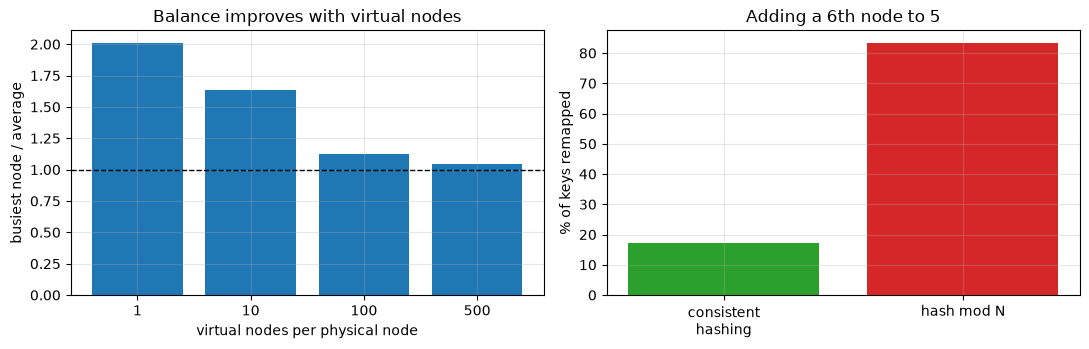

In [5]:
# What happens when we add a 6th node?
ring = ConsistentHashRing(nodes, vnodes=100)
before = {k: ring.lookup(k) for k in keys}
ring.add("F")
after = {k: ring.lookup(k) for k in keys}
moved = [k for k in keys if before[k] != after[k]]
assert all(after[k] == "F" for k in moved)                         # keys only ever move TO the new node

mod_before = {k: h64(k) % 5 for k in keys}
mod_after = {k: h64(k) % 6 for k in keys}
mod_moved = sum(mod_before[k] != mod_after[k] for k in keys)
print(f"consistent hashing: {len(moved)/len(keys):.1%} of keys moved (ideal 1/6 = {1/6:.1%}), all of them to F")
print(f"hash mod N (5->6) : {mod_moved/len(keys):.1%} of keys moved (theory 5/6 = {5/6:.1%})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar([str(v) for v in dist["vnodes per node"]], dist["max/mean load"], color="tab:blue")
ax[0].axhline(1, color="k", lw=1, ls="--"); ax[0].set_xlabel("virtual nodes per physical node")
ax[0].set_ylabel("busiest node / average"); ax[0].set_title("Balance improves with virtual nodes")
ax[1].bar(["consistent\nhashing", "hash mod N"], [len(moved)/len(keys)*100, mod_moved/len(keys)*100], color=["tab:green", "tab:red"])
ax[1].set_ylabel("% of keys remapped"); ax[1].set_title("Adding a 6th node to 5")
plt.tight_layout(); plt.show()

**What just happened?**
- With **1 virtual node** per server, ring positions are random, so one server owned far more keys than another (see the max/mean column of the first table). With 100 virtual nodes the busiest server is within about 12% of the average, and with 500 within about 4%.
- Adding a sixth node moved only about **one sixth** of the keys with consistent hashing, and every moved key went to the new node `F`; with `hash mod N` about **83%** of the keys moved (a key stays only if `h mod 5 == h mod 6`, i.e. for 5 out of every 30 hash values). For a cache, that is the difference between a small dip and a total cold start.

**Complexity:** lookup is O(log(N·V)) with binary search over N nodes × V virtual nodes; memory O(N·V). An alternative with no ring is **rendezvous (highest-random-weight) hashing**: pick the node with the highest `hash(key, node)`, O(N) per lookup, used e.g. by some CDNs.

---
## 3. Caching

*In plain English:* keep copies of popular answers somewhere fast, so the slow work is done only once.

A **cache** is a small, fast store holding copies of data that is expensive to fetch or compute. Analogy: the spices on your counter versus the supermarket. It works because real workloads are **skewed**: a small set of items gets most of the requests (**temporal locality**: recently used items are used again).

### 3.1 Caching patterns

| Pattern | Read path | Write path | Pros | Cons |
|---|---|---|---|---|
| **Cache-aside** (lazy loading) | app checks cache; on miss reads DB and fills cache | app writes DB, then **deletes** the cache entry | simple; cache holds only what is used; cache failure ≠ outage | first read is slow; possible stale data |
| **Read-through** | the *cache library* loads from DB on a miss | (combined with one of the below) | app code simpler | cache must know the DB |
| **Write-through** | from cache | write cache **and** DB synchronously | cache always fresh | every write pays both latencies; caches unread data |
| **Write-back** (write-behind) | from cache | write cache; flush to DB **later** in batches | fastest writes, absorbs bursts | data loss if the cache dies before flushing; complex |
| **Write-around** | cache-aside | write DB only | avoids filling cache with write-once data | recent writes miss |

Cache-aside is the default for web apps. Here it is with a **TTL** (time to live: entries expire after a fixed time, bounding staleness):

In [6]:
class FakeClock:
    def __init__(self): self.t = 0.0
    def now(self): return self.t
    def advance(self, s): self.t += s

class SlowDB:
    def __init__(self): self.data, self.reads = {"user:1": {"name": "Ayesha", "plan": "free"}}, 0
    def get(self, k): self.reads += 1; return dict(self.data[k])
    def put(self, k, v): self.data[k] = v

class CacheAside:
    def __init__(self, db, clock, ttl=60):
        self.db, self.clock, self.ttl, self.store = db, clock, ttl, {}       # store: key -> (value, expires_at)
    def get(self, k):
        hit = self.store.get(k)
        if hit and hit[1] > self.clock.now():
            return hit[0], "hit"
        value = self.db.get(k)                                               # miss or expired: go to the DB
        self.store[k] = (value, self.clock.now() + self.ttl)
        return value, "miss"
    def update(self, k, v):
        self.db.put(k, v)                                                    # 1. write the source of truth
        self.store.pop(k, None)                                              # 2. invalidate (delete, don't set)

clock, db = FakeClock(), SlowDB()
cache = CacheAside(db, clock, ttl=60)
log = []
for step, action in [(0, "get"), (1, "get"), (2, "update"), (3, "get"), (70, "get"), (75, "get")]:
    clock.t = step
    if action == "update":
        cache.update("user:1", {"name": "Ayesha", "plan": "pro"}); log.append((step, "update plan->pro", "-", db.reads))
    else:
        v, how = cache.get("user:1"); log.append((step, f"get -> plan={v['plan']}", how, db.reads))
print(pd.DataFrame(log, columns=["t (s)", "action", "cache", "DB reads so far"]).to_string(index=False))

 t (s)           action cache  DB reads so far
     0 get -> plan=free  miss                1
     1 get -> plan=free   hit                1
     2 update plan->pro     -                1
     3  get -> plan=pro  miss                2
    70  get -> plan=pro  miss                3
    75  get -> plan=pro   hit                3


**What just happened?** The first read missed and went to the DB; the second was a hit. The update wrote the DB and **deleted** the cache entry, so the next read fetched the new plan. At t=70 the entry (cached at t=3 with a 60 s TTL) had expired, so it was reloaded; at t=75 it was a hit again. Five reads from users cost only three DB reads; on a real skewed workload the ratio is far better.

> ⚠️ **Common mistake:** updating the cache *with the new value* instead of deleting it. Two concurrent writers can then leave the cache holding the older value forever (write A to DB, write B to DB, set cache B, set cache A). Deleting on write plus a TTL limits the damage. Also: the cache is not the source of truth; the system must still work (more slowly) when it is empty.

### 3.2 Eviction: LRU vs. LFU on a Zipf workload

When the cache is full, an **eviction policy** chooses the victim:
- **LRU** (least recently used): evict the item not used for the longest time. Adapts quickly to change.
- **LFU** (least frequently used): evict the item with the fewest uses. Keeps long-term favourites, but slow to forget old popularity.
- Others: FIFO, random, **ARC** (adaptive between recency and frequency), **W-TinyLFU** (the policy behind Java's Caffeine; a frequency sketch plus a small LRU window). Redis offers `allkeys-lru` and `allkeys-lfu` (both approximated by sampling).

Both are implemented in O(1) per operation: LRU with an ordered dictionary, LFU with one ordered dictionary per frequency.

In [7]:
class LRUCache:
    def __init__(self, capacity):
        self.cap, self.od, self.hits, self.misses = capacity, OrderedDict(), 0, 0
    def access(self, key):
        if key in self.od:
            self.od.move_to_end(key); self.hits += 1                  # most recently used goes to the end
        else:
            self.misses += 1
            self.od[key] = True
            if len(self.od) > self.cap: self.od.popitem(last=False)   # evict the front = least recent

class LFUCache:
    """O(1) LFU: key -> freq, and freq -> keys in recency order (ties broken by LRU)."""
    def __init__(self, capacity):
        self.cap, self.freq, self.buckets, self.min_f = capacity, {}, defaultdict(OrderedDict), 0
        self.hits = self.misses = 0
    def _touch(self, key):
        f = self.freq[key]
        del self.buckets[f][key]
        if not self.buckets[f]:
            del self.buckets[f]
            if self.min_f == f: self.min_f = f + 1                    # that frequency level is now empty
        self.freq[key] = f + 1; self.buckets[f + 1][key] = True
    def access(self, key):
        if key in self.freq:
            self.hits += 1; self._touch(key); return
        self.misses += 1
        if len(self.freq) >= self.cap:
            victim, _ = self.buckets[self.min_f].popitem(last=False)  # least frequent, then least recent
            if not self.buckets[self.min_f]: del self.buckets[self.min_f]
            del self.freq[victim]
        self.freq[key] = 1; self.buckets[1][key] = True; self.min_f = 1

def lfu_bruteforce(trace, cap):
    """Reference LFU: O(n) scan for (lowest freq, oldest use). Used only to test LFUCache."""
    freq, last, hits = {}, {}, 0
    for t, k in enumerate(trace):
        if k in freq: hits += 1; freq[k] += 1
        else:
            if len(freq) >= cap:
                victim = min(freq, key=lambda x: (freq[x], last[x])); del freq[victim]; del last[victim]
            freq[k] = 1
        last[k] = t
    return hits

# Correctness checks on random traces.
r = random.Random(SEED)
for trial in range(5):
    trace = [r.randrange(30) for _ in range(3000)]; cap = r.randint(2, 15)
    lru = LRUCache(cap); [lru.access(k) for k in trace]
    @lru_cache(maxsize=cap)
    def f(k): return k
    [f(k) for k in trace]
    assert lru.hits == f.cache_info().hits                              # matches functools.lru_cache
    lfu = LFUCache(cap); [lfu.access(k) for k in trace]
    assert lfu.hits == lfu_bruteforce(trace, cap)                      # matches the brute-force LFU
print("LRU matches functools.lru_cache and LFU matches the brute-force reference on 5 random traces")

LRU matches functools.lru_cache and LFU matches the brute-force reference on 5 random traces


 cache size  LRU (static)  LFU (static)  LRU (shifting)  LFU (shifting)
         10         0.130         0.259           0.133           0.135
         50         0.308         0.427           0.312           0.224
        100         0.389         0.498           0.393           0.313
        500         0.587         0.656           0.586           0.503
       1000         0.675         0.725           0.671           0.611
       2000         0.763         0.794           0.757           0.722


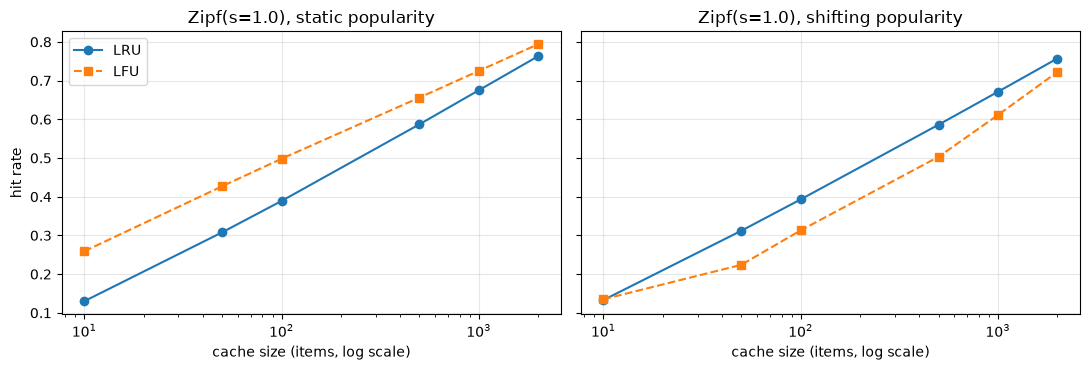

In [8]:
def zipf_trace(n_items, n_req, s, rng, ranking=None):
    p = 1 / np.arange(1, n_items + 1) ** s; p /= p.sum()                 # P(rank k) proportional to 1/k^s
    ranks = rng.choice(n_items, size=n_req, p=p)
    return (ranks if ranking is None else ranking[ranks]).tolist()      # optional: which item has which rank

rng = np.random.default_rng(SEED)
N_ITEMS, N_REQ = 10_000, 100_000
static = zipf_trace(N_ITEMS, N_REQ, 1.0, rng)
shifting = zipf_trace(N_ITEMS, N_REQ // 2, 1.0, rng) + \
           zipf_trace(N_ITEMS, N_REQ // 2, 1.0, rng, ranking=rng.permutation(N_ITEMS))   # popularity changes halfway

def hit_rate(cls, trace, cap):
    c = cls(cap)
    for k in trace: c.access(k)
    return c.hits / len(trace)

sizes = [10, 50, 100, 500, 1000, 2000]
res = pd.DataFrame([{"cache size": c, "LRU (static)": hit_rate(LRUCache, static, c), "LFU (static)": hit_rate(LFUCache, static, c),
                     "LRU (shifting)": hit_rate(LRUCache, shifting, c), "LFU (shifting)": hit_rate(LFUCache, shifting, c)}
                    for c in sizes]).round(3)
print(res.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, wl in zip(ax, ["static", "shifting"]):
    a.plot(res["cache size"], res[f"LRU ({wl})"], "o-", label="LRU")
    a.plot(res["cache size"], res[f"LFU ({wl})"], "s--", label="LFU")
    a.set_xscale("log"); a.set_xlabel("cache size (items, log scale)"); a.set_title(f"Zipf(s=1.0), {wl} popularity")
ax[0].set_ylabel("hit rate"); ax[0].legend(); plt.tight_layout(); plt.show()

**What just happened?**
- On the **static** Zipf workload, **LFU beats LRU at every cache size**: popularity never changes, so counting uses is the better predictor, while LRU sometimes evicts a popular item after a burst of one-off requests. Note how a cache holding just 1–5% of the items (100–500 of 10,000) already serves 39–66% of the requests: that is the power of skew.
- On the **shifting** workload (the popularity ranking is reshuffled halfway), LFU falls *behind* LRU at every size from 50 items up: items that were popular in the first half keep high counts and squat in the cache. LRU forgets quickly, so its hit rate barely changes. This is why production caches use hybrids (W-TinyLFU, ARC, LFU with decay/aging, as in Redis).

**Complexity:** both caches are O(1) per access and O(capacity) memory (plus the frequency map for LFU).

### 3.3 TTL, cache stampede and CDNs

**TTL** bounds staleness but creates a new problem: when a very hot key expires, hundreds of concurrent requests miss at the same moment and all hit the database together, a **cache stampede** (thundering herd, dog-piling). Let's create one with 50 threads.

In [9]:
def stampede(protect: bool, n_threads=50):
    cache, db_calls, lock = {}, [0], threading.Lock()
    key_locks = defaultdict(threading.Lock)
    barrier = threading.Barrier(n_threads)
    def slow_db():
        with lock: db_calls[0] += 1
        time.sleep(0.2)                                    # an expensive query
        return "homepage feed"
    def get():
        barrier.wait()                                     # all threads arrive at the same instant
        if "feed" in cache: return cache["feed"]
        if not protect:
            cache["feed"] = slow_db(); return cache["feed"]
        with key_locks["feed"]:                            # single-flight: one loader per key
            if "feed" not in cache:                        # double-check after acquiring the lock
                cache["feed"] = slow_db()
        return cache["feed"]
    threads = [threading.Thread(target=get) for _ in range(n_threads)]
    [t.start() for t in threads]; [t.join() for t in threads]
    return db_calls[0]

print("DB queries when a hot key expires under 50 concurrent requests:")
print("  no protection          :", stampede(protect=False))
print("  single-flight per key  :", stampede(protect=True))

DB queries when a hot key expires under 50 concurrent requests:


  no protection          : 50


  single-flight per key  : 1


**What just happened?** Without protection, every one of the 50 concurrent requests found the cache empty and ran the expensive query: 50x the load at the worst possible moment (the DB is slow *because* it is busy, so more requests pile up). With a per-key lock and a double-check (**single-flight** / request coalescing), one request recomputed the value and the other 49 waited and reused it.

Other stampede defences:
- **TTL jitter**: `ttl = 300 + random.uniform(0, 60)`, so keys written together do not expire together.
- **Stale-while-revalidate**: serve the old value while one background task refreshes it.
- **Probabilistic early expiration** (the "XFetch" algorithm): each request refreshes slightly early with a probability that grows as expiry approaches.

**CDN (content delivery network).** A CDN is a geographically distributed cache for HTTP responses: images, JS/CSS, video, also API responses marked cacheable. Users fetch from a nearby **edge** (~10–30 ms away) instead of your origin (~150 ms across an ocean). *Pull* CDNs fetch from the origin on a miss (most common); *push* CDNs are uploaded to ahead of time. You control them with `Cache-Control` headers (`public, max-age=86400, immutable` for content-addressed files like `app.3f9a1c.js`), and purge or version URLs to update content.

---
## 4. Databases at scale

*In plain English:* copy the data onto several machines so it survives failures, and split it up when it is too big for one.

The single-server theory is in the [DBMS fundamentals](../13_Databases/00_dbms_fundamentals/) notebooks: [transactions and concurrency control](../13_Databases/00_dbms_fundamentals/05_transactions_and_concurrency_control.ipynb), [recovery and storage](../13_Databases/00_dbms_fundamentals/06_recovery_and_storage.ipynb), [indexing](../13_Databases/00_dbms_fundamentals/07_indexing_b_trees_and_hashing.ipynb) and [distributed databases](../13_Databases/00_dbms_fundamentals/09_distributed_databases_warehousing_and_security.ipynb). Here we look at what changes when one database server is no longer enough.

### 4.1 Replication

**Replication** keeps copies of the same data on several machines, for **availability** (a copy survives a crash), **read scaling** (spread reads over copies) and **latency** (a copy near the user).

| Topology | Writes go to | Reads | Main risk | Examples |
|---|---|---|---|---|
| **Single-leader** (primary/replica) | the leader only | leader or followers (**read replicas**) | replication lag; failover | PostgreSQL, MySQL, MongoDB replica sets |
| **Multi-leader** | any leader (e.g. one per region) | any | write conflicts must be resolved | multi-region MySQL setups, CouchDB |
| **Leaderless** | several replicas directly (quorum) | several replicas (quorum) | stale reads if quorums are too small | Cassandra, DynamoDB-style stores |

Replication can be **synchronous** (the leader waits for followers to confirm: no data loss on failover, but slower and blocked if a follower is down) or **asynchronous** (fast, but recent writes can be lost on failover and followers lag behind). Lag causes a famous anomaly: you update your profile, the page reloads from a lagging replica, and your change is "gone". The fix is **read-your-writes consistency**: route a user's reads to the leader for a short time after they write.

In [10]:
def replica_reads(policy, n=20_000, seed=SEED):
    rng = np.random.default_rng(seed)
    lags = rng.exponential(0.2, size=(n, 2))                 # two async followers, mean lag 200 ms
    delay = rng.uniform(0, 1.0, n)                           # user reads 0-1 s after their own write
    replica = rng.integers(0, 3, n)                          # 0 = leader, 1-2 = followers (random routing)
    stale = 0
    for i in range(n):
        r = replica[i]
        if policy == "read-your-writes" and delay[i] < 2.0:  # recently wrote? -> read from the leader
            r = 0
        if r > 0 and delay[i] < lags[i, r - 1]:              # the follower has not applied the write yet
            stale += 1
    return stale / n

for p in ["any replica", "read-your-writes"]:
    print(f"{p:17}: {replica_reads(p):.1%} of reads-after-own-write returned stale data")

any replica      : 13.3% of reads-after-own-write returned stale data
read-your-writes : 0.0% of reads-after-own-write returned stale data


**What just happened?** With random routing, about two thirds of reads went to a follower, and some of those arrived before the follower had applied the write: **13.3%** of users "lost" their own update for a moment. Routing reads to the leader for a while after a user's own write made stale reads disappear for *that user* (other users can still see slightly old data, which is usually fine: that is **eventual consistency**). The cost is extra load on the leader, so the window is kept short or tracked per user with a "last write position".

### 4.2 Quorums in leaderless replication

With **N** replicas, a write waits for **W** acknowledgements and a read asks **R** replicas. If **W + R > N**, every read set overlaps every write set in at least one replica, so a read sees the latest acknowledged write (with versioning to pick the newest). Let's verify that rule by brute force over all subsets.

In [11]:
def always_overlap(n, w, r):
    nodes = range(n)
    return all(set(ws) & set(rs) for ws in itertools.combinations(nodes, w) for rs in itertools.combinations(nodes, r))

rows = []
for n in (3, 5):
    for w in range(1, n + 1):
        for r in range(1, n + 1):
            ok = always_overlap(n, w, r)
            assert ok == (w + r > n)                                   # the quorum condition, checked exhaustively
            if (n, w, r) in [(3, 1, 1), (3, 2, 2), (3, 3, 1), (3, 1, 3), (5, 3, 3), (5, 2, 3), (5, 1, 5)]:
                rows.append({"N": n, "W": w, "R": r, "W+R>N": w + r > n, "every read sees latest write": ok})
print(pd.DataFrame(rows).to_string(index=False))
print("Checked all (W, R) pairs for N=3 and N=5: overlap <=> W + R > N")

 N  W  R  W+R>N  every read sees latest write
 3  1  1  False                         False
 3  1  3   True                          True
 3  2  2   True                          True
 3  3  1   True                          True
 5  1  5   True                          True
 5  2  3  False                         False
 5  3  3   True                          True
Checked all (W, R) pairs for N=3 and N=5: overlap <=> W + R > N


**What just happened?** For every combination, "every read set intersects every write set" held exactly when W + R > N (pigeonhole principle: W + R > N slots cannot all be distinct among N replicas). Typical choices: N=3, W=2, R=2 tolerates one slow or dead replica for both reads and writes; W=1 favours write latency and availability at the cost of possibly stale reads. (Quorums alone do not give full linearisability; sloppy quorums and concurrent writes need more machinery, see Kleppmann ch. 5.)

### 4.3 Sharding (partitioning) and hot keys

When data or write load outgrows one machine, split it: **sharding** puts different rows on different machines (**partitions/shards**), each usually replicated.

| Strategy | How | Pros | Cons |
|---|---|---|---|
| **Range** | key ranges: A–F, G–M, ... or by date | range scans are cheap | hot spots (all new writes hit the "latest" range) |
| **Hash** | `hash(key)` → shard (with consistent hashing, §2.2) | even spread | range queries hit every shard |
| **Directory / lookup** | a table maps key → shard | flexible moves, tenant placement | the directory is a dependency |
| **Geographic** | by user region | latency, data residency laws | uneven region sizes |

Choose the **shard key** from your main access pattern (e.g. `user_id` for a per-user app, so one user's data lives on one shard). Cross-shard joins and transactions become expensive. Even with a perfect hash, **hot keys** remain: one celebrity or one viral item can overload its shard. Let's measure it.

In [12]:
rng = np.random.default_rng(SEED)
n_users, n_req, n_shards = 100_000, 1_000_000, 8
p = 1 / np.arange(1, n_users + 1) ** 1.1; p /= p.sum()                      # Zipf(1.1) user activity
users = rng.choice(n_users, size=n_req, p=p)
user_counts = np.bincount(users, minlength=n_users)
shard_of = np.array([h64(f"user:{u}") % n_shards for u in range(n_users)])
load = np.bincount(shard_of, weights=user_counts, minlength=n_shards)

hot = int(np.argmax(user_counts))                                           # the "celebrity"
salted = load.copy(); salted[shard_of[hot]] -= user_counts[hot]
salted += user_counts[hot] / n_shards                                       # key salting: hot#0..hot#7 on all shards
print(f"hottest user = {user_counts[hot] / n_req:.1%} of all requests")
print("shard load / mean, plain hash :", np.round(load / load.mean(), 2), "max", round(load.max() / load.mean(), 2))
print("shard load / mean, salted key :", np.round(salted / salted.mean(), 2), "max", round(salted.max() / salted.mean(), 2))

hottest user = 13.5% of all requests
shard load / mean, plain hash : [0.62 1.18 0.75 0.63 1.35 1.74 1.1  0.62] max 1.74
shard load / mean, salted key : [0.75 1.32 0.89 0.77 1.49 0.8  1.24 0.75] max 1.49


**What just happened?** Hashing spread 100,000 users over 8 shards, but user activity follows a Zipf law: the single most active user alone produced **13.5%** of all requests, and the busiest shard carried **1.74x** the average load. **Key salting** (store or count the hot key as `hot#0 ... hot#7`, spread over all shards, and combine on read) cut that to **1.49x**. The remaining imbalance comes from the next-hottest users, so in practice you salt or cache the *top-k* hot keys, not just one. Other remedies: cache hot reads in front of the shard, replicate hot items more, or give known celebrities special handling (we will see this again in the news feed).

### 4.4 Indexes in one minute

An **index** (usually a B+ tree) turns a full table scan, O(n), into a tree search, O(log n), at the cost of extra storage and slower writes. How B+ trees and hash indexes work is in [DBMS 07](../13_Databases/00_dbms_fundamentals/07_indexing_b_trees_and_hashing.ipynb); composite indexes and when *not* to index are in [22/03](../22_ML_System_Design/03_relational_db_design.ipynb). The effect is easy to see with SQLite's query planner:

In [13]:
con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE users (id INTEGER PRIMARY KEY, email TEXT, plan TEXT)")
con.executemany("INSERT INTO users (email, plan) VALUES (?, ?)", ((f"u{i}@example.com", "free") for i in range(200_000)))
q = "SELECT id FROM users WHERE email = ?"
lookups = [f"u{i}@example.com" for i in range(0, 200_000, 10_000)]          # 20 lookups

def timed():
    t0 = time.perf_counter()
    for e in lookups: con.execute(q, (e,)).fetchone()
    return (time.perf_counter() - t0) / len(lookups) * 1e3                      # ms per lookup

plan0 = con.execute("EXPLAIN QUERY PLAN " + q, ("x",)).fetchall()[0][-1]; t_scan = timed()
con.execute("CREATE INDEX idx_users_email ON users(email)")
plan1 = con.execute("EXPLAIN QUERY PLAN " + q, ("x",)).fetchall()[0][-1]; t_idx = timed()
print(f"without index: {plan0:45} {t_scan:.3f} ms per lookup")
print(f"with index   : {plan1:45} {t_idx:.4f} ms per lookup  ({t_scan / t_idx:,.0f}x faster)")
con.close()

without index: SCAN users                                    29.442 ms per lookup
with index   : SEARCH users USING COVERING INDEX idx_users_email (email=?) 0.0061 ms per lookup  (4,809x faster)


**What just happened?** Without the index the planner had to `SCAN users` (read all 200,000 rows for each lookup); with it, it used `SEARCH users USING COVERING INDEX idx_users_email` (a B-tree descent: about 3 levels and ~18 key comparisons in total; "covering" because the index entry already contains the row id we asked for). The speed-up printed above is in the hundreds to thousands, and it grows with the table size.

### 4.5 SQL or NoSQL?

| Choose a relational DB (PostgreSQL, MySQL) when | Choose a NoSQL store when |
|---|---|
| data is relational, needs joins and ad-hoc queries | access is by key, with known, simple patterns |
| you need multi-row ACID transactions (payments, inventory) | you need massive write throughput or horizontal scale beyond one primary (Cassandra, DynamoDB) |
| the schema is fairly stable; integrity constraints matter | flexible or nested documents (MongoDB), graphs (Neo4j), time series, vectors |
| scale fits one primary + replicas (this covers most companies!) | you accept eventual consistency or design around it |

Modern systems are mostly **polyglot**: PostgreSQL for core data, Redis for caching and rate limits, object storage for blobs, a search or vector index, a warehouse for analytics. See [22/04](../22_ML_System_Design/04_nosql_and_data_stores.ipynb) and [NoSQL databases](../13_Databases/02_nosql/01_nosql_databases.ipynb). PostgreSQL alone (with JSONB, full-text search and `pgvector`) is a strong default for an early-stage AI product.

### 4.6 CAP and PACELC, stated precisely

[22/01](../22_ML_System_Design/01_hld_ml_systems.ipynb) introduces CAP and [DBMS 09](../13_Databases/00_dbms_fundamentals/09_distributed_databases_warehousing_and_security.ipynb) covers CAP, PACELC, quorums and two-phase commit from the database-theory side; here is the compact version a system designer needs.
- **CAP theorem** (Brewer 2000; proved by Gilbert & Lynch 2002): in a distributed data store, when a **network partition** occurs, you cannot have both **consistency** (here: *linearisability*, every read sees the latest write as if there were one copy) and **availability** (every request to a non-failed node gets a non-error response). Partitions are not optional in real networks, so the real choice is *what to give up during a partition*: **CP** (refuse some requests) or **AP** (answer, possibly with stale data). "Pick 2 of 3" is a misleading slogan: when there is no partition you can have both.
- **PACELC** (Abadi 2012) completes the picture: **if P**artition, choose **A** or **C**; **E**lse (normal operation), choose **L**atency or **C**onsistency. Synchronous replication buys consistency with latency even on a good day.

| System (typical default configuration) | PACELC | Why |
|---|---|---|
| Cassandra, DynamoDB (eventually consistent reads) | PA/EL | tunable quorums; defaults favour availability and low latency |
| Google Spanner, CockroachDB | PC/EC | consensus (Paxos/Raft) on every write; Spanner adds TrueTime |
| PostgreSQL primary + async read replicas | primary is PC/EC; reads from replicas behave PA/EL | replicas can lag |
| Single-node PostgreSQL | not distributed (CAP does not apply) | one copy, ACID |

> 🎓 **Exam / interview tip:** do not say "MongoDB is CP" or "Cassandra is AP" as absolutes: most stores let you tune it per request (Cassandra `QUORUM` vs `ONE`, DynamoDB strongly consistent reads, MongoDB read/write concerns). Say which guarantee *your feature* needs: "a bank balance needs linearisable writes; a like counter can be eventually consistent".

---
## 5. Asynchronous processing

*In plain English:* for work that can wait, write it on a ticket, put it in a queue, and let background workers handle it.

Not everything must happen while the user waits. Thumbnails, emails, embeddings for new documents, fine-tuning jobs and webhooks can be done **asynchronously**: the request handler records the work in a **message queue** and returns immediately (often `202 Accepted` with a job ID); **workers** process it in the background. Benefits: lower latency, absorbing bursts (the queue is a buffer), independent scaling of workers, retries without bothering the user.

| | **Message queue (point-to-point)** | **Publish/subscribe (pub/sub)** |
|---|---|---|
| Delivery | each message goes to **one** consumer (of a group) | each message goes to **every** subscriber |
| Use | task distribution: "resize this image" | events: "order placed" → billing, email, analytics each react |
| Examples | RabbitMQ queues, AWS SQS, Celery, Redis lists | Kafka topics (consumer groups give both), Google Pub/Sub, SNS, Redis pub/sub |

**Delivery guarantees:**
- **At-most-once**: send and forget; messages may be lost, never duplicated (metrics sampling).
- **At-least-once**: the consumer **acknowledges** after processing; if the ack is lost or the worker crashes, the message is redelivered, so **duplicates happen**. This is the standard.
- **Exactly-once**: no loss, no duplicates. End-to-end it is impossible in general over an unreliable network (a sender cannot know whether a lost ack means "not processed" or "processed, ack lost"; cf. the Two Generals problem). Systems such as Kafka offer exactly-once *within* their own boundary via transactions; across systems you get **effectively-once = at-least-once + idempotent processing**.

An operation is **idempotent** if doing it twice has the same effect as doing it once (`SET balance = 100` is; `balance += 10` is not). To make a non-idempotent handler safe, the producer attaches an **idempotency key** (unique per logical operation, e.g. `payment_id`), and the consumer records processed keys *atomically with the effect* and skips repeats. Messages that keep failing go to a **dead-letter queue (DLQ)** after N attempts, so one "poison" message cannot block the queue forever; humans inspect and replay them.

Let's simulate a payment worker with `queue.Queue`: transient failures, lost acknowledgements (→ duplicates) and two poison messages.

In [14]:
@dataclass
class Message:
    id: str
    amount: float | None
    attempts: int = 0

def run_worker(idempotent: bool, n_msgs=30, max_attempts=5, seed=SEED):
    rnd = random.Random(seed)
    q, dlq = queue.Queue(), queue.Queue()
    for i in range(n_msgs):
        q.put(Message(f"pay-{i:03d}", None if i in (7, 19) else 10.0))    # two malformed "poison" messages
    stats = Counter({"duplicates skipped": 0}); charged = defaultdict(float); processed_keys = set()

    def handle(msg):
        if msg.amount is None: raise ValueError("malformed payload")      # fails every time
        if rnd.random() < 0.2: raise TimeoutError("bank API timeout")      # transient failure
        if idempotent:
            if msg.id in processed_keys:                                   # duplicate delivery -> no-op
                stats["duplicates skipped"] += 1; return
            processed_keys.add(msg.id)                                     # (atomically with the charge in real life)
        charged[msg.id] += msg.amount

    def worker():
        while True:
            msg = q.get()
            if msg is None: q.task_done(); break                           # sentinel: stop
            try:
                handle(msg)
                stats["processed ok"] += 1
                if rnd.random() < 0.15:                                    # ack lost -> broker redelivers
                    stats["redelivered (ack lost)"] += 1; q.put(msg)
            except Exception:
                msg.attempts += 1; stats["failures"] += 1
                (dlq if msg.attempts >= max_attempts else q).put(msg)     # retry, or park in the DLQ
            q.task_done()

    t = threading.Thread(target=worker); t.start()
    q.join()                                                               # wait until every message (incl. retries) is done
    q.put(None); t.join()                                                  # then stop the worker
    return {"handler": "idempotent" if idempotent else "naive",
            "total charged": sum(charged.values()), "expected": 10.0 * (n_msgs - 2),
            "customers charged twice+": sum(v > 10 for v in charged.values()),
            "in DLQ": [m.id for m in list(dlq.queue)], **stats}

print(pd.DataFrame([run_worker(False), run_worker(True)]).fillna(0).T.to_string(header=False))

handler                                naive          idempotent
total charged                          340.0               280.0
expected                               280.0               280.0
customers charged twice+                   6                   0
in DLQ                    [pay-007, pay-019]  [pay-007, pay-019]
duplicates skipped                         0                   6
processed ok                              34                  34
redelivered (ack lost)                     6                   6
failures                                  16                  16


**What just happened?** Both runs saw the same sequence of random events (same seed). The broker redelivered 6 messages after their acks were "lost". The **naive** handler charged those 6 customers again, so it collected 340 instead of the expected 280. The **idempotent** handler recognised the repeated `payment_id`s, skipped them, and charged exactly 280. In both runs the transient timeouts were retried successfully, while the two malformed messages failed five times each and ended up in the **DLQ** instead of looping forever.

> ⚠️ **Common mistake:** storing the idempotency key and performing the effect in two separate steps. If the worker crashes between them, you either charge twice or never. Put both in **one database transaction** (or use the downstream API's own idempotency key, as payment providers offer). Also give keys a retention period and make DLQ alerts page someone.

**Related patterns:** the **transactional outbox** (write the event to an `outbox` table in the same DB transaction as the business change; a relay publishes it, avoiding "DB updated but event lost"); **sagas** for multi-service workflows with compensating actions; **backpressure** (bounded queues that slow producers down).

---
## 6. Rate limiting and resilience patterns

*In plain English:* protect the system from too much traffic and from broken neighbours, so one problem does not spread.

### 6.1 Five rate-limiting algorithms

A **rate limiter** caps how many requests a client (user, API key, IP, tenant) may make per unit of time, protecting availability, fairness and cost (§5.2 and §7.6 of [the security notebook](08_security_for_ai_applications.ipynb) show why LLM apps need it). Rejected requests get **HTTP 429 Too Many Requests** with a `Retry-After` header.

| Algorithm | Idea | State per client |
|---|---|---|
| **Token bucket** | a bucket holds up to *b* tokens, refilled at *r* tokens/s; each request spends one | 2 numbers (tokens, last refill time) |
| **Leaky bucket** (as a queue) | requests join a FIFO of size *b* that drains at *r*/s; full → reject | a queue (or a counter + timestamp in the "meter" form) |
| **Fixed window counter** | count requests per calendar window (e.g. per second); reset at the boundary | 1 counter + window id |
| **Sliding window log** | keep timestamps of accepted requests in the last *w* seconds | up to *limit* timestamps |
| **Sliding window counter** | estimate = current window count + previous count × overlap fraction | 2 counters |

All five are implemented below with an explicit `now` argument, so the simulation is deterministic. The limit is **10 requests per second** in every case.

In [15]:
class TokenBucket:
    def __init__(self, rate, capacity):
        self.rate, self.cap, self.tokens, self.last = rate, capacity, capacity, 0.0
    def allow(self, now):
        self.tokens = min(self.cap, self.tokens + (now - self.last) * self.rate)   # lazy refill
        self.last = now
        if self.tokens >= 1: self.tokens -= 1; return True
        return False

class LeakyBucketQueue:
    """Requests wait in a bounded FIFO that drains at `rate`; returns departure time or None if rejected."""
    def __init__(self, rate, capacity):
        self.interval, self.cap, self.next_free, self.departures = 1 / rate, capacity, 0.0, deque()
    def allow(self, now):
        while self.departures and self.departures[0] <= now: self.departures.popleft()  # already left
        if len(self.departures) >= self.cap: return None                               # queue full
        depart = max(now, self.next_free); self.next_free = depart + self.interval
        self.departures.append(depart); return depart                                  # smoothed output time

class FixedWindow:
    def __init__(self, limit, window=1.0):
        self.limit, self.window, self.win_id, self.count = limit, window, None, 0
    def allow(self, now):
        w = int(now // self.window)
        if w != self.win_id: self.win_id, self.count = w, 0                 # new window: reset
        if self.count < self.limit: self.count += 1; return True
        return False

class SlidingWindowLog:
    def __init__(self, limit, window=1.0):
        self.limit, self.window, self.log = limit, window, deque()
    def allow(self, now):
        while self.log and self.log[0] <= now - self.window: self.log.popleft()
        if len(self.log) < self.limit: self.log.append(now); return True
        return False

class SlidingWindowCounter:
    def __init__(self, limit, window=1.0):
        self.limit, self.window, self.win_id, self.cur, self.prev = limit, window, 0, 0, 0
    def allow(self, now):
        w = int(now // self.window)
        if w != self.win_id:
            self.prev = self.cur if w == self.win_id + 1 else 0                 # previous window's count
            self.cur, self.win_id = 0, w
        elapsed = (now % self.window) / self.window                             # fraction of the current window
        estimate = self.cur + self.prev * (1 - elapsed)                         # weighted overlap
        if estimate < self.limit: self.cur += 1; return True
        return False

# Traffic: steady 5 req/s, then 20 requests straddling the 10 s boundary, then 25 req/s overload.
trace = [round(t, 3) for t in np.arange(0, 9.5, 0.2)]                         # 5 req/s for 9.5 s
trace += [round(9.5 + i * 0.05, 3) for i in range(20)]                        # 20 requests in 9.50-10.45 s
trace += [round(t, 3) for t in np.arange(12, 17, 0.04)]                        # 25 req/s for 5 s
trace.sort()

def max_in_any_second(times):
    times, best, j = sorted(times), 0, 0
    for i in range(len(times)):
        while times[i] - times[j] >= 1.0 - 1e-9: j += 1          # half-open window [t, t+1), float-safe
        best = max(best, i - j + 1)
    return best

results, accepted_times = [], {}
for name, lim in [("token bucket", TokenBucket(10, 10)), ("leaky bucket (queue)", LeakyBucketQueue(10, 10)),
                  ("fixed window", FixedWindow(10)), ("sliding window log", SlidingWindowLog(10)),
                  ("sliding window counter", SlidingWindowCounter(10))]:
    out = [(t, lim.allow(t)) for t in trace]
    if name.startswith("leaky"):
        acc = [d for _, d in out if d is not None]                            # when requests leave the queue
        delays = [d - t for t, d in out if d is not None]
    else:
        acc = [t for t, ok in out if ok]; delays = [0]
    accepted_times[name] = acc
    results.append({"algorithm": name, "accepted": len(acc), "rejected": len(trace) - len(acc),
                    "max accepted in any 1 s": max_in_any_second(acc), "max added delay (s)": round(max(delays), 2)})
print(f"{len(trace)} requests; limit 10 req/s")
print(pd.DataFrame(results).to_string(index=False))

193 requests; limit 10 req/s
             algorithm  accepted  rejected  max accepted in any 1 s  max added delay (s)
          token bucket       126        67                       19                  0.0
  leaky bucket (queue)       128        65                       10                  1.0
          fixed window       115        78                       17                  0.0
    sliding window log       108        85                       10                  0.0
sliding window counter       110        83                       12                  0.0


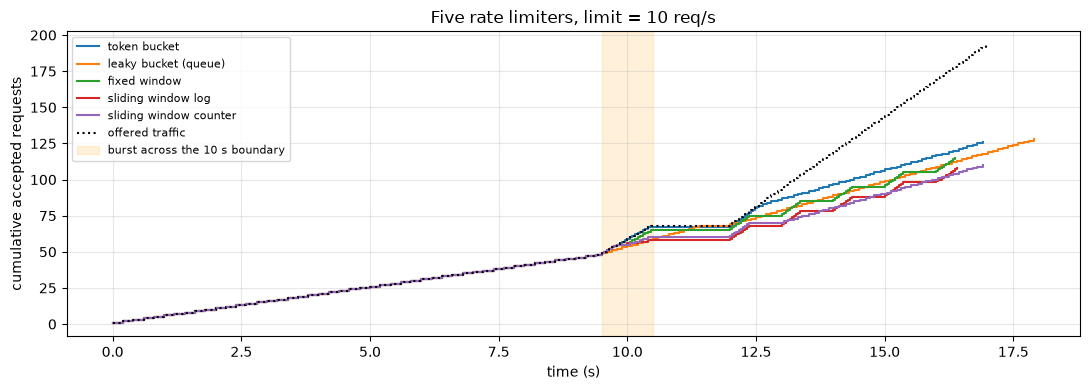

In [16]:
fig, ax = plt.subplots(figsize=(11, 4))
for name, acc in accepted_times.items():
    ax.step(sorted(acc), np.arange(1, len(acc) + 1), where="post", label=name)
ax.step(trace, np.arange(1, len(trace) + 1), where="post", color="k", ls=":", label="offered traffic")
ax.axvspan(9.5, 10.5, color="orange", alpha=0.15, label="burst across the 10 s boundary")
ax.set_xlabel("time (s)"); ax.set_ylabel("cumulative accepted requests"); ax.set_title("Five rate limiters, limit = 10 req/s")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

**What just happened?** Read the table column by column.
- **Max accepted in any 1 s.** The **sliding window log** is the only exact *admission* limiter: never more than 10 in any one-second interval (the leaky bucket's *output* also stays at 10 per second, because it releases requests at a fixed pace). The **fixed window** let through more than the limit around the 10 s boundary (the end of one window plus the start of the next): the classic boundary problem, up to 2x the limit in the worst case. The **token bucket** also allowed a burst above 10 per second, *by design*: a full bucket (10 tokens) plus refill during the second, up to capacity + rate. That is often what you want (users are bursty), but the burst size is a parameter you must choose. The **sliding window counter** approximates the log with just two counters and stayed close to the limit.
- **Max added delay.** The **leaky bucket** rejected the fewest requests here because it *queues* them instead (up to the queue size) and releases them at a perfectly smooth 10 per second (the flat slope in the plot), at the cost of added latency. It is a traffic *shaper*, ideal in front of a fixed-capacity backend such as a GPU pool.

| Algorithm | Exact? | Bursts | Memory per client | Typical use |
|---|---|---|---|---|
| Token bucket | no (allows bursts up to *b*) | yes, controlled | O(1) | API gateways (AWS, Stripe), per-user limits |
| Leaky bucket (queue) | smooth output | absorbed by the queue | O(b) | traffic shaping, protecting fixed capacity |
| Fixed window | no (2x at boundaries) | at boundaries | O(1) | simple quotas ("1,000 per day") |
| Sliding window log | **yes** | no | O(limit) | low limits where exactness matters (logins) |
| Sliding window counter | approximately | small | O(1) | large-scale limiters (Cloudflare described this approach) |

### 6.2 Circuit breaker

When a dependency is down, calling it anyway wastes threads, adds latency (every call waits for a timeout) and hammers the dependency while it tries to recover. A **circuit breaker** (popularised by Michael Nygard's *Release It!*) wraps calls and has three states:

```
          failures >= threshold                   cool-down elapsed
 CLOSED -------------------------> OPEN ---------------------------> HALF-OPEN
 (calls pass)                    (fail fast,                        (let ONE trial call through)
    ^                             no calls)                            |          |
    |------------------ trial succeeds --------------------------------+          |
                                   ^------------------- trial fails ---------------+
```

In [17]:
class CircuitBreaker:
    def __init__(self, threshold=5, cooldown=10.0):
        self.threshold, self.cooldown = threshold, cooldown
        self.state, self.failures, self.opened_at = "CLOSED", 0, None
    def call(self, fn, now):
        if self.state == "OPEN":
            if now - self.opened_at < self.cooldown:
                return "fast-fail"                                   # don't even try
            self.state = "HALF_OPEN"                                 # cool-down over: allow one trial
        try:
            fn(now)
        except Exception:
            self.failures += 1
            if self.state == "HALF_OPEN" or self.failures >= self.threshold:
                self.state, self.opened_at = "OPEN", now             # trip (or re-trip)
            return "error"
        self.state, self.failures = "CLOSED", 0                      # success closes the circuit
        return "ok"

def flaky_service(now):
    if 20 <= now < 60: raise ConnectionError("dependency down")      # outage from t=20 s to t=60 s

cb, events, outage_calls, fast_fails = CircuitBreaker(), [], 0, 0
for t in range(100):                                                 # one call per second
    before = cb.state
    result = cb.call(flaky_service, t)
    fast_fails += result == "fast-fail"
    if 20 <= t < 60 and result != "fast-fail": outage_calls += 1     # calls that hit the broken dependency
    if result != "fast-fail" and (before != "CLOSED" or cb.state != "CLOSED" or result == "error"):
        events.append({"t (s)": t, "state before": before, "result": result, "state after": cb.state})
print(pd.DataFrame(events).to_string(index=False))
print(f"calls reaching the dependency during the 40 s outage: without breaker 40, with breaker {outage_calls}; "
      f"fast-fails returned instantly: {fast_fails}")

 t (s) state before result state after
    20       CLOSED  error      CLOSED
    21       CLOSED  error      CLOSED
    22       CLOSED  error      CLOSED
    23       CLOSED  error      CLOSED
    24       CLOSED  error        OPEN
    34         OPEN  error        OPEN
    44         OPEN  error        OPEN
    54         OPEN  error        OPEN
    64         OPEN     ok      CLOSED
calls reaching the dependency during the 40 s outage: without breaker 40, with breaker 8; fast-fails returned instantly: 36


**What just happened?** The breaker tripped to **OPEN** after the 5th consecutive failure (t=24 s). From then on calls failed fast without touching the dependency, except for one **HALF_OPEN** trial every 10 s (t=34, 44, 54), each of which failed and re-opened the circuit. The first trial after the outage ended (t=64) succeeded and **closed** the circuit. During the 40-second outage only 8 calls reached the struggling dependency instead of 40, and callers got instant errors (which they can turn into a fallback, e.g. a cached answer or a smaller model) instead of waiting for timeouts.

### 6.3 Retries with exponential backoff and jitter, timeouts and bulkheads

**Retries** fix transient failures, but naive retries cause **retry storms**: if 1,000 clients fail at the same moment and all retry after exactly 1 s, 2 s, 4 s ..., the server is hit by synchronised waves. **Exponential backoff** spreads attempts out over growing intervals; **jitter** (randomness) desynchronises clients. AWS's analysis recommends *full jitter*: `sleep = random.uniform(0, min(cap, base * 2**attempt))`.

no jitter  : busiest 0.5 s bucket = 1000, busiest bucket after t=2 s = 1000 retries


full jitter: busiest 0.5 s bucket =  700, busiest bucket after t=2 s =  314 retries


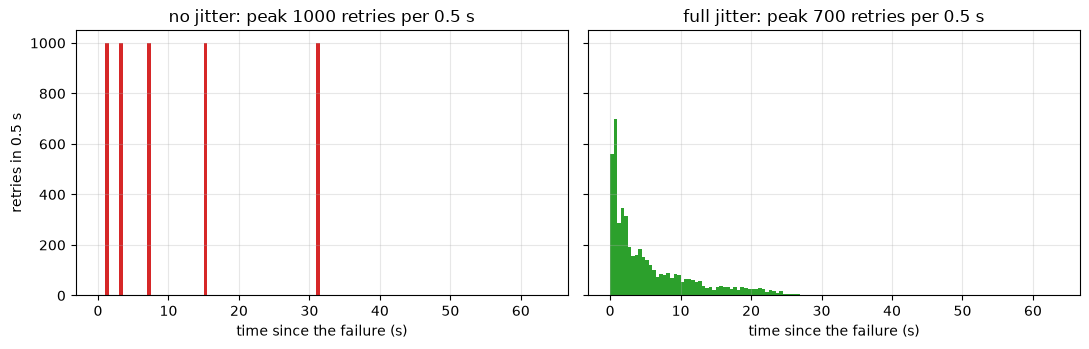

In [18]:
def retry_times(n_clients=1000, attempts=5, base=1.0, cap=32.0, jitter=True, seed=SEED):
    rnd, times = random.Random(seed), []
    for _ in range(n_clients):
        t = 0.0
        for a in range(attempts):
            backoff = min(cap, base * 2 ** a)
            t += rnd.uniform(0, backoff) if jitter else backoff        # full jitter vs. plain exponential
            times.append(t)
    return np.array(times)

bins = np.arange(0, 64, 0.5)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, jit in zip(ax, [False, True]):
    ts = retry_times(jitter=jit)
    counts, _ = np.histogram(ts, bins=bins)
    a.bar(bins[:-1], counts, width=0.5, align="edge", color="tab:red" if not jit else "tab:green")
    a.set_title(f"{'no jitter' if not jit else 'full jitter'}: peak {counts.max()} retries per 0.5 s")
    a.set_xlabel("time since the failure (s)")
    later = counts[bins[:-1] >= 2.0].max()                                # waves after the first 2 seconds
    print(f"{'no jitter  ' if not jit else 'full jitter'}: busiest 0.5 s bucket = {counts.max():4d}, "
          f"busiest bucket after t=2 s = {later:4d} retries")
ax[0].set_ylabel("retries in 0.5 s"); plt.tight_layout(); plt.show()

**What just happened?** Without jitter, all 1,000 clients retried in the *same* half-second bucket each time (1, 3, 7, 15, 31 s): five spikes of 1,000 requests at a server that is already struggling. With full jitter the same 5,000 retries were spread out. The first second is still crowded (700 retries in the busiest half-second, because the first backoff is at most 1 s), but every later wave is flattened: after t = 2 s no half-second sees more than 314 retries, versus 1,000 without jitter, and the load keeps falling as the backoff windows grow.

Rules for retries: retry only **idempotent** operations (or use idempotency keys, §5); retry only retryable errors (timeouts, 429, 503; not 400); cap attempts and total time; honour `Retry-After`; use a **retry budget** (e.g. retries ≤ 10% of requests) so retries cannot multiply load; never retry at every layer of a deep call chain (3 layers × 3 retries = 27 attempts).

**Timeouts.** Every network call needs one; the default in many libraries is "wait forever" (`requests` has no timeout unless you pass one; `httpx` defaults to 5 s). Set it from the dependency's latency distribution (a bit above its p99), and propagate a **deadline** through the call chain, so downstream services stop working on requests whose caller has already given up.

**Bulkheads.** Ship hulls are divided into watertight compartments so one leak does not sink the ship. In software, give each dependency its own **bounded pool** (threads, connections, semaphores), so a slow dependency exhausts only its own pool:

In [19]:
def slow_dep(): time.sleep(0.3); return "slow"
def fast_dep(): time.sleep(0.01); return "fast"

def fast_latency(bulkhead: bool):
    shared = ThreadPoolExecutor(max_workers=4)
    slow_pool = ThreadPoolExecutor(max_workers=2) if bulkhead else shared   # separate compartments
    fast_pool = ThreadPoolExecutor(max_workers=2) if bulkhead else shared
    for _ in range(8): slow_pool.submit(slow_dep)                           # a slow dependency floods its pool
    t0 = time.perf_counter()
    futures = [fast_pool.submit(fast_dep) for _ in range(4)]
    [f.result() for f in futures]
    elapsed = time.perf_counter() - t0
    for p in {shared, slow_pool, fast_pool}: p.shutdown(wait=True)
    return elapsed

print(f"4 fast calls behind 8 slow ones, one shared pool of 4 : {fast_latency(False):.2f} s")
print(f"4 fast calls with bulkheads (2 + 2 workers)          : {fast_latency(True):.2f} s")

4 fast calls behind 8 slow ones, one shared pool of 4 : 0.61 s


4 fast calls with bulkheads (2 + 2 workers)          : 0.02 s


**What just happened?** With one shared pool, the 8 slow calls occupied all 4 workers and the fast calls had to wait behind them (two rounds of 0.3 s), so a healthy dependency looked slow. With bulkheads the fast calls had their own 2 workers and finished in a few hundredths of a second. The same idea at larger scale: separate connection pools per downstream, separate worker pools for interactive vs. batch jobs, separate GPU queues for free vs. paid users.

---
## 7. Observability, SLOs and availability

*In plain English:* measure what the system is doing, and agree in numbers how reliable it must be.

**Observability** is the ability to understand a system's internal state from the data it emits. Its three pillars:

| Pillar | What | Answers | Tools |
|---|---|---|---|
| **Logs** | timestamped, structured events (JSON lines) | *what happened* to this request? | ELK/OpenSearch, Loki, Cloud Logging |
| **Metrics** | numeric time series (counters, gauges, histograms) | *how much / how fast*, trends, alerts | Prometheus + Grafana, Datadog |
| **Traces** | the path of one request across services, as a tree of timed **spans** | *where* did the time go? | OpenTelemetry (the standard), Jaeger, Tempo, Langfuse for LLM calls |

Which metrics? Google's **four golden signals**: **latency, traffic, errors, saturation**. For request-driven services, **RED** (rate, errors, duration); for resources, **USE** (utilisation, saturation, errors). [Agent observability](../10_Agents/06_agent_observability.ipynb) applies this to LLM agents.

A trace makes latency visible. Here is a tiny tracer with a fake clock, rendering one chat request as a waterfall:

In [20]:
class Tracer:
    def __init__(self): self.t, self.spans, self.stack = 0.0, [], []
    def work(self, ms): self.t += ms                                     # simulate time spent
    def span(self, name):
        tracer = self
        class _Span:
            def __enter__(s):
                s.rec = {"name": name, "depth": len(tracer.stack), "start": tracer.t}
                tracer.stack.append(s.rec); tracer.spans.append(s.rec); return s
            def __exit__(s, *exc):
                s.rec["end"] = tracer.t; tracer.stack.pop()
        return _Span()

tr = Tracer()
with tr.span("POST /chat"):
    with tr.span("auth (JWT verify)"): tr.work(2)
    with tr.span("rate limit (Redis)"): tr.work(1)
    with tr.span("retrieve"):
        with tr.span("embed query"): tr.work(18)
        with tr.span("vector search"): tr.work(35)
    with tr.span("LLM call (streamed)"):
        with tr.span("queue wait"): tr.work(120)
        with tr.span("time to first token"): tr.work(230)
        with tr.span("generate 300 tokens"): tr.work(300 * 12)
    with tr.span("save message (DB)"): tr.work(6)

total = tr.spans[0]["end"]
for s in tr.spans:
    a, b = int(s["start"] / total * 50), max(1, int((s["end"] - s["start"]) / total * 50))
    print(f"{'  ' * s['depth'] + s['name']:28} {s['end'] - s['start']:7.0f} ms |{' ' * a}{'#' * b}")

POST /chat                      4012 ms |##################################################
  auth (JWT verify)                2 ms |#
  rate limit (Redis)               1 ms |#
  retrieve                        53 ms |#
    embed query                   18 ms |#
    vector search                 35 ms |#
  LLM call (streamed)           3950 ms |#################################################
    queue wait                   120 ms |#
    time to first token          230 ms |  ##
    generate 300 tokens         3600 ms |     ############################################
  save message (DB)                6 ms |                                                 #


**What just happened?** The waterfall shows at a glance that retrieval (53 ms) and auth are irrelevant: the request took about 4 s, and **token generation** (3.6 s) dominates, followed by time to first token and queue wait. Optimising the vector search would be wasted effort; streaming (so the user sees the first words after ~0.4 s), a smaller/faster model or shorter answers would not. Always measure before optimising.

### 7.1 Percentiles, not averages

Latency distributions are skewed, so the **mean** hides the slow requests users actually complain about. Report **percentiles**: p50 (median), p95, p99. ([22/08 §7](../22_ML_System_Design/08_industry_system_design_case_study.ipynb) shows how tail latency compounds across services.)

{'mean': '112 ms', 'p50': '81 ms', 'p95': '163 ms', 'p99': '1113 ms', 'max': '4166 ms'}


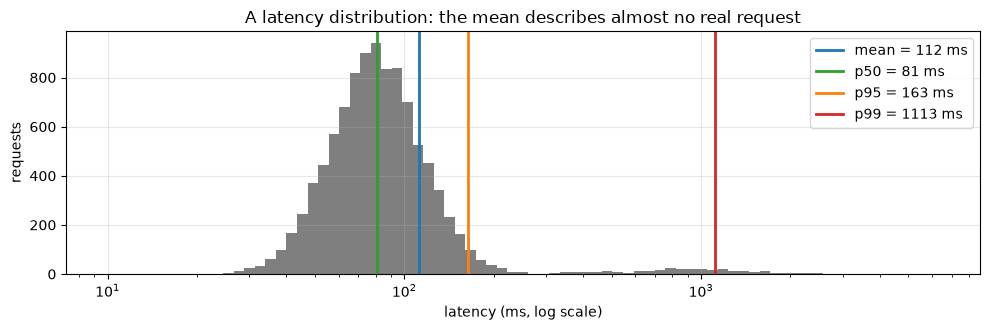

In [21]:
rng = np.random.default_rng(SEED)
lat = np.concatenate([rng.lognormal(np.log(80), 0.35, 9_700),               # normal requests ~80 ms
                      rng.lognormal(np.log(900), 0.5, 300)])                 # 3% hit a slow path (GC, cold cache)
stats = {"mean": lat.mean(), "p50": np.percentile(lat, 50), "p95": np.percentile(lat, 95),
         "p99": np.percentile(lat, 99), "max": lat.max()}
print({k: f"{v:.0f} ms" for k, v in stats.items()})
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(lat, bins=np.logspace(1, 3.8, 80), color="tab:gray")
for k, c in [("mean", "tab:blue"), ("p50", "tab:green"), ("p95", "tab:orange"), ("p99", "tab:red")]:
    ax.axvline(stats[k], color=c, lw=2, label=f"{k} = {stats[k]:.0f} ms")
ax.set_xscale("log"); ax.set_xlabel("latency (ms, log scale)"); ax.set_ylabel("requests")
ax.set_title("A latency distribution: the mean describes almost no real request"); ax.legend(); plt.tight_layout(); plt.show()

**What just happened?** The median request took about 80 ms, but the mean is pulled up by the 3% slow path to a value that matches almost no actual request, and p99 is around a second: one user in a hundred waits over 10x the median. If a page makes 20 such calls, most page loads include at least one slow call (1 − 0.99^20 ≈ 18% of pages hit a p99 call). Alert and set objectives on percentiles.

### 7.2 SLIs, SLOs and error budgets

- An **SLI** (service level *indicator*) is a measured quantity: "fraction of `/chat` requests that succeed in < 2 s".
- An **SLO** (service level *objective*) is the target for an SLI over a window: "99.9% over 30 days".
- An **SLA** (service level *agreement*) is a contract with consequences (refunds) and is looser than the SLO.
- The **error budget** is 1 − SLO: the amount of unreliability you are *allowed*. While budget remains, ship features; when it is spent, prioritise reliability. The **burn rate** is how fast you spend it: error rate ÷ (1 − SLO). A burn rate of 1 spends exactly the budget over the window.

Worked example: a chat API with an average 500 requests/s and an SLO of 99.9% over 30 days.

In [22]:
slo, window_days, rps = 0.999, 30, 500
requests_window = rps * 86_400 * window_days
budget_requests = (1 - slo) * requests_window
budget_minutes = (1 - slo) * window_days * 24 * 60
print(f"requests in 30 days      : {requests_window:,.0f}")
print(f"error budget             : {budget_requests:,.0f} failed requests  (= {budget_minutes:.1f} minutes of full outage)")

# An incident: 5% of requests fail for 20 minutes.
inc_err, inc_min = 0.05, 20
failed = rps * 60 * inc_min * inc_err
burn = inc_err / (1 - slo)
print(f"incident                 : {failed:,.0f} failed requests = {failed / budget_requests:.1%} of the monthly budget")
print(f"burn rate during incident: {burn:.0f}x -> would exhaust the whole budget in {window_days * 24 / burn:.1f} hours")

# Multi-window burn-rate alerts (Google SRE Workbook): page fast for fast burns, ticket for slow burns.
alerts = pd.DataFrame([
    {"alert": "page", "long window": "1 h", "short window": "5 min", "burn rate >": 14.4},
    {"alert": "page", "long window": "6 h", "short window": "30 min", "burn rate >": 6.0},
    {"alert": "ticket", "long window": "3 days", "short window": "6 h", "burn rate >": 1.0},
])
long_hours = {"1 h": 1, "6 h": 6, "3 days": 72}
alerts["budget spent when it fires"] = [f"{b * long_hours[w] / (window_days * 24):.0%}" for b, w in zip(alerts["burn rate >"], alerts["long window"])]
print(alerts.to_string(index=False))

requests in 30 days      : 1,296,000,000
error budget             : 1,296,000 failed requests  (= 43.2 minutes of full outage)
incident                 : 30,000 failed requests = 2.3% of the monthly budget
burn rate during incident: 50x -> would exhaust the whole budget in 14.4 hours
 alert long window short window  burn rate > budget spent when it fires
  page         1 h        5 min         14.4                         2%
  page         6 h       30 min          6.0                         5%
ticket      3 days          6 h          1.0                        10%


**What just happened?** At 500 requests/s, 30 days is 1.296 billion requests, so a 99.9% SLO allows **1,296,000 failed requests**, or **43.2 minutes** of total outage. The incident (5% errors for 20 minutes) failed 30,000 requests, only **2.3%** of the budget, but its **burn rate of 50x** would have used up the whole month's budget in **14.4 hours** had it continued. The alert table is the standard recipe from the Google SRE Workbook: page a human if the burn rate exceeds 14.4 over the last hour (2% of the monthly budget gone in one hour) *and* over the last 5 minutes (so the page stops quickly once fixed); open a ticket for slow burns.

### 7.3 Availability: the nines

**Availability** = uptime / total time. Each extra "nine" cuts allowed downtime tenfold, and costs a lot more than the previous one.

In [23]:
rows = []
for a in [0.9, 0.99, 0.999, 0.9995, 0.9999, 0.99999]:
    down = 1 - a
    rows.append({"availability": f"{a * 100:g}%", "per year": f"{down * 365.25 * 24:.2f} h" if down * 365.25 * 24 >= 1 else f"{down * 365.25 * 24 * 60:.1f} min",
                 "per 30 days": f"{down * 30 * 24 * 60:.1f} min", "per week": f"{down * 7 * 24 * 60:.2f} min",
                 "per day": f"{down * 86_400:.1f} s"})
print(pd.DataFrame(rows).to_string(index=False))

series = 0.999 ** 3                                     # API -> DB -> LLM provider, all required
parallel = 1 - (1 - 0.99) ** 2                          # two independent replicas, either is enough
print(f"\nthree 99.9% dependencies in SERIES   : {series:.4%}  (worse than any one of them)")
print(f"two 99% replicas in PARALLEL         : {parallel:.4%}  (better than either)")

availability per year per 30 days    per week  per day
         90% 876.60 h  4320.0 min 1008.00 min 8640.0 s
         99%  87.66 h   432.0 min  100.80 min  864.0 s
       99.9%   8.77 h    43.2 min   10.08 min   86.4 s
      99.95%   4.38 h    21.6 min    5.04 min   43.2 s
      99.99% 52.6 min     4.3 min    1.01 min    8.6 s
     99.999%  5.3 min     0.4 min    0.10 min    0.9 s

three 99.9% dependencies in SERIES   : 99.7003%  (worse than any one of them)
two 99% replicas in PARALLEL         : 99.9900%  (better than either)


**What just happened?** 99.9% ("three nines") allows 43.2 minutes of downtime per 30 days; 99.99% only 4.3 minutes, too short for a human to even respond, so four nines requires automated failover. Composition matters: components that are all *required* multiply (three 99.9% dependencies give 99.70%), while *redundant* components combine as 1 − product of failure probabilities (two independent 99% replicas give 99.99%). Your SLO cannot exceed what your critical dependencies (including the LLM provider!) give you, unless you add redundancy such as a fallback model.

---
## 8. Case studies (compact)

*In plain English:* apply the same toolkit to five classic apps, from a link shortener to a ChatGPT-style assistant.

Each case study follows the method from §1 in miniature. In an interview you would spend 35–45 minutes on one; here we highlight the decisions that make each one interesting.

### 8.1 URL shortener (e.g. bit.ly)

**Requirements.** Functional: create a short link for a long URL; redirect; optional custom alias and expiry. Non-functional: redirects are fast (p99 < 50 ms) and highly available; links never collide; read-heavy.

In [24]:
new_per_month, read_write = 100e6, 100
writes = new_per_month / (30 * 86_400); reads = writes * read_write
storage_5y_tb = new_per_month * 12 * 5 * 500 / 1e12           # ~500 bytes per record
print(f"writes ~{writes:.0f}/s, reads ~{reads:,.0f}/s (avg); 5-year storage ~{storage_5y_tb:.0f} TB; "
      f"62^7 = {62**7:,} possible 7-char codes")

ALPHABET = "0123456789abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ"   # base62: URL-safe, no symbols
def base62_encode(n: int) -> str:
    if n == 0: return ALPHABET[0]
    out = []
    while n: n, r = divmod(n, 62); out.append(ALPHABET[r])
    return "".join(reversed(out))
def base62_decode(s: str) -> int:
    n = 0
    for ch in s: n = n * 62 + ALPHABET.index(ch)
    return n

def snowflake_id(ms_since_epoch: int, machine: int, seq: int) -> int:
    """Twitter-style 64-bit ID: 41 bits time | 10 bits machine | 12 bits sequence. Unique without coordination."""
    assert machine < 2**10 and seq < 2**12
    return (ms_since_epoch << 22) | (machine << 12) | seq

for n in [0, 61, 62, 125, 3_521_614_606_207]:
    assert base62_decode(base62_encode(n)) == n                                    # round-trip check
print("counter 125 ->", base62_encode(125), "| largest 7-char code ->", base62_encode(62**7 - 1))
sid = snowflake_id(1_793_000_000_000 - 1_288_834_974_657, machine=17, seq=3)       # ms since Twitter's epoch
print("snowflake id:", sid, "-> short code", base62_encode(sid), f"({len(base62_encode(sid))} chars)")

writes ~39/s, reads ~3,858/s (avg); 5-year storage ~3 TB; 62^7 = 3,521,614,606,208 possible 7-char codes
counter 125 -> 21 | largest 7-char code -> ZZZZZZZ
snowflake id: 2114621382456315907 -> short code 2wcZhhkv6RJ (11 chars)


**What just happened?** ~39 writes/s and ~3,900 reads/s on average: small, and the whole dataset (~3 TB over five years) fits in one sharded key-value store. Seven base62 characters give 3.5 trillion codes, enough for millennia at this rate.

**Key design decisions:**
- **Generating the code.** (a) *Counter + base62*: unique by construction; use a distributed ID generator (pre-allocated ranges per server, or Snowflake-style IDs, which are 11 characters in base62) so there is no single counter bottleneck. Sequential codes are guessable, so if links are private, add randomness. (b) *Hash the URL* (e.g. first 7 base62 chars of SHA-256): the same URL gets the same code, but collisions must be detected and retried. (c) *Random 7 characters* + uniqueness check on insert.
- **Data model:** `short_code (PK) → long_url, owner, created_at, expires_at` in a key-value or wide-column store; reads are pure key lookups.
- **Redirect:** **301** (permanent) lets browsers cache it, reducing load but hiding analytics; **302/307** (temporary) sends every click to you, which is what analytics-driven shorteners use.
- **Read path:** CDN/edge → cache (hot links follow a Zipf law, §3) → KV store. **Abuse:** scan target URLs against malware/phishing lists and rate-limit creation.

### 8.2 Chat system (e.g. WhatsApp, Slack)

**Requirements.** 1:1 and group messages, online presence, delivery/read receipts, history on all devices, push notifications when offline. Non-functional: low delivery latency (< 200 ms in-region), messages never lost, per-conversation ordering.

In [25]:
dau, msgs_per_user, msg_bytes, peak = 50e6, 40, 200, 3
msgs_day = dau * msgs_per_user
concurrent = dau * 0.2                                      # assume 20% of DAU online at peak
per_gateway = 50_000                                        # WebSocket connections per gateway server (conservative)
print(f"messages/day {msgs_day:,.0f} -> {msgs_day / 86_400:,.0f}/s avg, {msgs_day / 86_400 * peak:,.0f}/s peak")
print(f"storage {msgs_day * msg_bytes / 1e9:,.0f} GB/day ({msgs_day * msg_bytes * 365 / 1e12:,.0f} TB/year before replication)")
print(f"{concurrent:,.0f} concurrent connections -> ~{concurrent / per_gateway:,.0f} gateway servers at {per_gateway:,} each")

messages/day 2,000,000,000 -> 23,148/s avg, 69,444/s peak
storage 400 GB/day (146 TB/year before replication)
10,000,000 concurrent connections -> ~200 gateway servers at 50,000 each


**What just happened?** 2 billion messages a day is ~23k/s on average and ~69k/s at peak; storage grows by ~400 GB a day; and 10 million open connections need ~200 connection gateways. The persistent connections, not the message rate, shape the architecture.

```
 phone --WebSocket--> [ gateway servers (stateful: hold connections) ] <--> [ session registry: user -> gateway ]
                              |                                                     ^
                              v                                                     |
                     [ chat service ] --append--> [ message store, partitioned by conversation_id ]
                              |
                              +--> [ pub/sub / queue ] --> recipient's gateway (online)  or  [ push notification service ] (offline)
```

**Key design decisions:**
- **Transport:** WebSockets (or long polling as a fallback) because the server must push; gateways are the only *stateful* tier, so keep them thin and look up "which gateway holds user X" in a registry.
- **Ordering:** a per-conversation **sequence number** assigned by the conversation's owner shard; clients sort and detect gaps. Global ordering is unnecessary and expensive.
- **Storage:** wide-column store partitioned by `conversation_id`, clustered by `message_id` (Cassandra/ScyllaDB; Discord publicly described moving trillions of messages to ScyllaDB). Large groups: fan out on read rather than writing one copy per member.
- **Delivery:** at-least-once with client-generated message IDs for de-duplication (§5); receipts are just more messages. **Presence:** heartbeats with a TTL in a cache, fanned out lazily (only to contacts who are looking). **Security:** end-to-end encryption (Signal protocol) means the server stores ciphertext only.

### 8.3 News feed (e.g. X/Twitter, Instagram)

**Requirements.** Users post; each user sees a feed of recent posts from people they follow, newest or ranked first. Read-heavy; feed load p99 < 300 ms; a few seconds of delay before a post appears is acceptable.

The central decision is **when** to assemble feeds:
- **Fan-out on write (push):** when someone posts, insert the post ID into every follower's precomputed feed (a list in Redis). Reads are one fast lookup; writes cost one insert per follower.
- **Fan-out on read (pull):** at read time, fetch recent posts of everyone you follow and merge. Writes are cheap; reads are expensive.
- **Hybrid:** push for normal users, pull for **celebrities** (accounts with huge follower counts), merged at read time.

Follower counts are extremely skewed, so let's compute the cost of each strategy on a synthetic social graph.

In [26]:
rng = np.random.default_rng(SEED)
n_users = 1_000_000
followers = np.minimum(rng.pareto(1.2, n_users) * 20, 50e6).astype(np.int64)       # heavy-tailed follower counts
posts_per_day = rng.poisson(0.5, n_users)                                           # posts per user per day
feed_loads_per_user, followees_per_user = 10, max(1, int(followers.sum() / n_users))  # avg followees = avg followers
celebrity = followers > 100_000

push_writes = int((posts_per_day * followers).sum())                      # one feed insert per follower per post
pull_reads = n_users * feed_loads_per_user * followees_per_user           # each feed load reads every followee
celeb_share_of_follows = followers[celebrity].sum() / followers.sum()
hybrid_writes = int((posts_per_day * followers)[~celebrity].sum())        # push only for non-celebrities
hybrid_reads = int(n_users * feed_loads_per_user * followees_per_user * celeb_share_of_follows)  # pull the celebrities
print(f"users {n_users:,}; median followers {np.median(followers):.0f}; max {followers.max():,}; "
      f"celebrities (>100k followers) {celebrity.sum()} = {celebrity.mean():.3%} of users")
print(pd.DataFrame([
    {"strategy": "fan-out on write", "feed inserts/day": push_writes, "post fetches at read time/day": 0},
    {"strategy": "fan-out on read", "feed inserts/day": 0, "post fetches at read time/day": pull_reads},
    {"strategy": "hybrid (pull celebrities)", "feed inserts/day": hybrid_writes, "post fetches at read time/day": hybrid_reads},
]).to_string(index=False))
print(f"celebrities hold {celeb_share_of_follows:.0%} of all follow edges; "
      f"pushing their posts costs {1 - hybrid_writes / push_writes:.0%} of all fan-out writes")

users 1,000,000; median followers 15; max 2,543,695; celebrities (>100k followers) 35 = 0.003% of users
                 strategy  feed inserts/day  post fetches at read time/day
         fan-out on write          44934267                              0
          fan-out on read                 0                      900000000
hybrid (pull celebrities)          39098037                      128834074
celebrities hold 14% of all follow edges; pushing their posts costs 13% of all fan-out writes


**What just happened?** The median user has 15 followers, but the tail is extreme: just **35 accounts (0.003% of users) hold 14% of all follow relationships**, and the biggest has 2.5 million followers. Pure fan-out on write costs ~45 million feed inserts a day, 13% of them for those 35 accounts, and a single celebrity post means millions of inserts within seconds (a **write hot spot**). Pure fan-out on read avoids that but makes every feed load fetch from every followee: 900 million fetches a day. The **hybrid** drops the celebrity fan-out (39 million inserts) and pays with ~129 million read-time fetches, one seventh of the pure-pull cost, and they all target the same few celebrity timelines, which are the easiest content in the system to cache. This is the approach Twitter described publicly.

Other pieces: a **post store** (sharded by post ID, media in object storage behind a CDN), a **social graph store**, the **feed cache** (only the latest ~500 IDs per user; older pages are rebuilt on demand), and a **ranking** stage (ML models re-order candidates; see [learning to rank](../03_Machine_Learning/01_supervised/12_learning_to_rank.ipynb)). Inactive users' feeds need not be precomputed at all.

### 8.4 Rate limiter as a service

**Requirements.** Limit each API key to N requests (or LLM tokens) per window across a fleet of API servers; add < 1–2 ms latency; keep working if the limiter's store hiccups; return helpful headers.

**Key design decisions:**
- **Where:** in the API gateway or as middleware/sidecar (one place for all services), before expensive work. Limits per user, per API key, per IP, per tenant, per endpoint, and for LLM apps **per token**, not just per request.
- **Algorithm and state:** token bucket or sliding-window counter (§6.1) in a shared, fast store (Redis). The read-modify-write must be **atomic**: a Redis Lua script or `INCR` + `EXPIRE`; otherwise two servers can both read "9 used" and both allow request 10.
- **Latency and scale:** a network round trip per request is the cost. At very high volume, keep **local token buckets** on each server that sync with the global store periodically (approximate but cheap), and shard counters by key (§2.2).
- **Failure mode:** if Redis is down, **fail open** (allow, protect availability; typical for public APIs) or **fail closed** (deny; right for expensive LLM calls or login attempts). Decide explicitly.
- **Responses:** `429 Too Many Requests`, `Retry-After`, and quota headers (the IETF `RateLimit`/`RateLimit-Policy` fields, still an Internet-Draft; many APIs use `X-RateLimit-Limit/Remaining/Reset`).

In [27]:
keys, bytes_per_key = 10e6, 32 + 16 + 64        # key name + (tokens, timestamp) + store overhead (rough)
checks_per_s = 200_000
print(f"state for {keys:,.0f} active keys ~ {keys * bytes_per_key / 1e9:.1f} GB  -> fits in one Redis node's RAM; "
      f"{checks_per_s:,} checks/s -> shard over a few nodes for throughput and redundancy")

state for 10,000,000 active keys ~ 1.1 GB  -> fits in one Redis node's RAM; 200,000 checks/s -> shard over a few nodes for throughput and redundancy


**What just happened?** Even ten million active keys need only about a gigabyte of state, so memory is not the problem; throughput and availability of the shared store are, which is why it is sharded and replicated.

### 8.5 LLM chat app (e.g. a ChatGPT-style assistant)

**Requirements.** Functional: multi-turn chat, streamed answers, conversation history, file upload/RAG (optional). Non-functional: **time to first token (TTFT)** < 1 s at p95; smooth streaming (**time per output token, TPOT**, ~20–50 ms); 99.9% availability; cost per conversation under control; abuse and prompt-injection defences ([security](08_security_for_ai_applications.ipynb)).

```
 browser --SSE/WebSocket--> [ API gateway: auth, token-based rate limits ] --> [ chat service (stateless) ]
                                                                                  |   |   |
                                [ conversation DB ] <--------- history -----------+   |   +--> [ exact / semantic cache ]
                                                                                      v
                                              [ GPU request queue + admission control (priorities, per-tenant quotas) ]
                                                                                      |
                                [ inference replicas: vLLM / TGI / SGLang, continuous batching, KV cache, prefix cache ]
                                       (or an external LLM API, with a fallback provider/model)
```

**Key design decisions:**
- **Streaming:** tokens are sent as they are generated via **Server-Sent Events** (simple, HTTP-friendly, what most LLM APIs use) or WebSockets. Users perceive TTFT, not total time (§7 waterfall).
- **GPU queue:** GPUs are the scarce, expensive resource. Requests wait in a queue with **admission control** (reject or degrade when the queue is too long, rather than letting everyone time out), priorities (paid > free) and per-tenant fairness. Inference servers use **continuous batching**: new sequences join the running batch at every decoding step, so one GPU serves dozens of streams ([inference optimisation](../08_LLM/13_inference_optimization.ipynb)).
- **Caching:** an *exact* cache for repeated prompts (FAQ-like traffic); a *semantic* cache (embedding similarity) with a strict threshold and tenant isolation; and **prompt/prefix caching** of the long shared system prompt and conversation history, either inside the inference server (KV cache reuse) or as a provider feature with discounted cached input tokens.
- **History:** do not resend unbounded history: truncate or summarise old turns; this is also the main cost driver because input tokens grow with every turn.

Estimation and cost, with **hypothetical** prices and throughput (replace them with your provider's and your own benchmarks):

In [28]:
dau, msgs, peak = 1e6, 20, 3
tok_in, tok_out = 1_500, 400                     # per request: prompt incl. history, and answer
price_in, price_out = 3.00, 15.00                # hypothetical API prices, $ per million tokens
rps_avg = dau * msgs / 86_400
out_tok_s_peak = rps_avg * peak * tok_out        # output tokens per second the fleet must generate at peak
replica_tok_s = 2_500                            # assumed aggregate decode throughput of one GPU replica (batched)
gpu_hour = 2.50                                  # assumed $ per GPU-hour

api_cost = tok_in / 1e6 * price_in + tok_out / 1e6 * price_out
cached_in = 1_000                                # shared prefix (system prompt + old history) served from the prompt cache
api_cost_cached = (cached_in * 0.1 + (tok_in - cached_in)) / 1e6 * price_in + tok_out / 1e6 * price_out   # cached input billed at 10% (assumption)
replicas_peak = math.ceil(out_tok_s_peak / replica_tok_s)
utilisation = 1 / peak                           # fleet sized for peak, average load is a third of it
self_cost = gpu_hour / (replica_tok_s * 3600 * utilisation) * tok_out   # decode-only, crude

print(f"requests: {rps_avg:,.0f}/s avg, {rps_avg * peak:,.0f}/s peak -> {out_tok_s_peak:,.0f} output tokens/s at peak")
print(f"self-hosted: ~{replicas_peak} GPU replicas at peak ({replica_tok_s:,} tok/s each)")
print(f"API cost per request          : ${api_cost:.4f}  -> ${api_cost * dau * msgs:,.0f} per day")
print(f"  with prompt caching         : ${api_cost_cached:.4f}  ({1 - api_cost_cached / api_cost:.0%} cheaper)")
print(f"  with 10% exact-cache hits   : ${api_cost_cached * 0.9:.4f} per request on average")
print(f"self-hosted (decode only, {utilisation:.0%} avg utilisation): ${self_cost:.5f} per request + engineers, prefill, redundancy")

requests: 231/s avg, 694/s peak -> 277,778 output tokens/s at peak
self-hosted: ~112 GPU replicas at peak (2,500 tok/s each)
API cost per request          : $0.0105  -> $210,000 per day
  with prompt caching         : $0.0078  (26% cheaper)
  with 10% exact-cache hits   : $0.0070 per request on average
self-hosted (decode only, 33% avg utilisation): $0.00033 per request + engineers, prefill, redundancy


**What just happened?** One million users sending 20 messages a day is only ~231 requests/s on average (~694/s at peak), but at 400 output tokens each that is ~278,000 output tokens per second at peak, about **112 GPU replicas** at the assumed throughput. At the hypothetical API prices one request costs about **$0.0105** (about $210,000 a day). Caching the 1,000-token shared prefix cuts that by about **26%**, and exact-cache hits shave off more. The self-hosted per-request number looks dramatically cheaper, but it ignores prefill compute, redundancy, idle capacity outside peak (we assumed the fleet is sized for peak), model quality differences and the engineering team: real comparisons need benchmarks, and many teams start with an API and move hot paths to self-hosted models later.

How many replicas do we need for a good **queue wait**? Here is a small discrete-event simulation of the GPU queue for a smaller deployment (50 requests/s), where each replica runs 64 sequences at once:

offered load ~ 459 concurrent sequences = 7.2 replicas' worth of slots


 replicas  utilisation  p50 wait (s)  p95 wait (s)  p99 wait (s)
        6         1.00         50.03         94.55         97.77
        7         1.00          1.88          3.86          4.15
        8         0.88          0.00          0.00          0.00
        9         0.78          0.00          0.00          0.00
       10         0.70          0.00          0.00          0.00
       11         0.64          0.00          0.00          0.00
       12         0.58          0.00          0.00          0.00


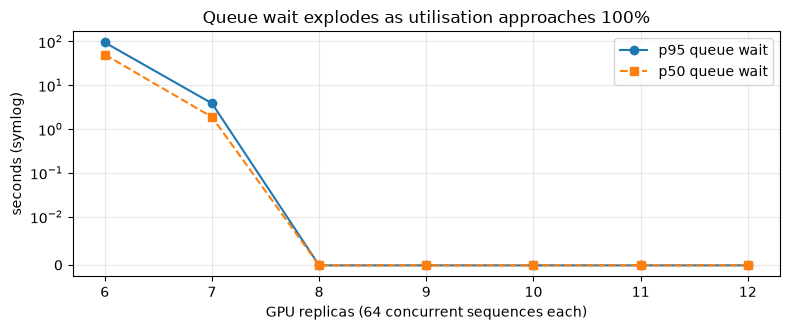

In [29]:
def gpu_queue(n_replicas, rate=50.0, slots_per_replica=64, n_req=30_000, seed=SEED):
    rng = np.random.default_rng(seed)
    arrivals = np.cumsum(rng.exponential(1 / rate, n_req))
    out_tokens = np.clip(rng.lognormal(np.log(300), 0.6, n_req), 10, 1024)   # answer lengths, capped by max_tokens
    service = 0.2 + out_tokens * 0.025                                         # prefill + 25 ms per token
    free = [0.0] * (n_replicas * slots_per_replica)                            # when each batch slot is free
    heapq.heapify(free)
    waits = np.empty(n_req)
    for i, (t, s) in enumerate(zip(arrivals, service)):                        # FIFO: next request takes the first free slot
        start = max(t, heapq.heappop(free))
        waits[i] = start - t
        heapq.heappush(free, start + s)
    busy = (service.sum() / (n_replicas * slots_per_replica)) / arrivals[-1]   # offered utilisation
    return {"replicas": n_replicas, "utilisation": round(min(busy, 1.0), 2), "p50 wait (s)": round(np.percentile(waits, 50), 2),
            "p95 wait (s)": round(np.percentile(waits, 95), 2), "p99 wait (s)": round(np.percentile(waits, 99), 2)}

offered = 50 * (0.2 + 0.025 * np.exp(np.log(300) + 0.6**2 / 2))
print(f"offered load ~ {offered:.0f} concurrent sequences = {offered / 64:.1f} replicas' worth of slots")
gq = pd.DataFrame([gpu_queue(r) for r in range(6, 13)])
print(gq.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(gq["replicas"], gq["p95 wait (s)"], "o-", label="p95 queue wait"); ax.plot(gq["replicas"], gq["p50 wait (s)"], "s--", label="p50 queue wait")
ax.set_yscale("symlog", linthresh=0.01); ax.set_xlabel("GPU replicas (64 concurrent sequences each)"); ax.set_ylabel("seconds (symlog)")
ax.set_title("Queue wait explodes as utilisation approaches 100%"); ax.legend(); plt.tight_layout(); plt.show()

**What just happened?** The offered load is about **7.2 replicas'** worth of batch slots. With 6 replicas the queue grows without bound for the whole simulation: median wait 50 s, p95 95 s (no SLO survives that; this is when **admission control** must reject or degrade). With 7 replicas we are still just *below* the offered load, so the queue still grows, only slowly (p95 ~4 s and rising). From 8 replicas (88% utilisation) the queue wait practically disappears, because 64 slots per replica absorb random bursts well. This is the queueing-theory "hockey stick" ([22/08 §8](../22_ML_System_Design/08_industry_system_design_case_study.ipynb) derives it for M/M/1): plan for 60–80% utilisation at peak, not 100%, and autoscale on queue depth rather than CPU.

**Remaining deep dives for this design:** fallbacks (a second provider or a smaller model when the primary is down, behind a circuit breaker, §6.2); per-user **token budgets** and abuse limits; storing conversations (append-only per conversation, like the chat system); evaluation and monitoring of answer quality ([LLMOps](../15_MLOps/13_llmops.ipynb)); safety guardrails in the request path.

---
## 9. Interview checklist

*In plain English:* a list to tick off in an interview, then the big picture and practice.

| Phase | Did you ...? |
|---|---|
| Requirements | clarify users, core features, and what is **out of scope**; state non-functional targets with numbers (DAU, p99, availability, consistency, durability) |
| Estimation | compute average and peak QPS, read/write ratio, storage growth, bandwidth, cache memory; turn each number into a decision |
| API | define the main endpoints, pagination (cursor), idempotency keys for writes, versioning, auth, rate limits |
| Data | list entities and access patterns; choose stores per pattern; pick shard keys; plan indexes |
| High-level design | draw clients, LB, stateless services, caches, DBs, queues, workers, CDN; walk one request end to end |
| Deep dives | go deep on the hardest 2–3 parts; compare at least two alternatives with trade-offs |
| Scale | find bottlenecks and single points of failure; replication, sharding, hot keys, caching, async processing |
| Reliability | timeouts, retries with backoff + jitter, circuit breakers, bulkheads, graceful degradation, multi-AZ |
| Consistency | where you need strong consistency vs. where eventual is fine; CAP/PACELC choice per component |
| Operations | SLIs/SLOs, metrics, logs, traces, alerts on burn rate; deployment strategy; security and abuse |
| Communication | think out loud, check in with the interviewer, keep the diagram up to date, summarise at the end |

## 🔗 How this connects to modern AI

- **LLM serving is a distributed-systems problem**: continuous batching and admission control are queueing; prefix-aware routing is consistent hashing; KV-cache reuse is caching with eviction (vLLM's PagedAttention manages GPU memory like an OS manages pages); multi-provider fallbacks are circuit breakers.
- **Token-based rate limits and budgets** (§6.1) are how every LLM API protects its GPUs, and how your app should protect its bill.
- **RAG pipelines** are asynchronous systems: document ingestion, chunking and embedding run through queues with idempotency and DLQs; vector indexes are sharded and replicated like any database ([vector databases](../22_ML_System_Design/05_vector_databases.ipynb)).
- **Agents** call many tools in sequence, so availability composes in series (§7.3) and timeouts, retries and idempotency are essential, especially for tools with side effects.
- **Observability for LLMs** adds token counts, TTFT/TPOT, cost per request and quality scores to the classic golden signals ([agent observability](../10_Agents/06_agent_observability.ipynb), [LLMOps](../15_MLOps/13_llmops.ipynb)).

## Recap

- Approach every design the same way: **requirements → estimation → API → data model → high-level design → deep dives → bottlenecks**, and make every estimate drive a decision.
- Scale out with **stateless** services behind a **load balancer**; least connections / power of two choices beat round robin when request lengths vary; **consistent hashing** moves only ~1/N of keys when nodes change, while `mod N` moves almost all of them.
- **Caching**: cache-aside + delete-on-write + TTL is the default; LFU wins on stable skew, LRU adapts to change; prevent **stampedes** with single-flight, jitter or stale-while-revalidate; CDNs serve static and cacheable content from the edge.
- **Databases**: replication for availability and reads (watch replication lag; read-your-writes); quorums need **W + R > N**; **sharding** for write scale, with hot keys handled by salting/caching; CAP is about partitions, PACELC adds the latency/consistency trade-off of normal operation.
- **Async**: queues buffer and decouple; at-least-once delivery + **idempotency keys** = effectively-once; **DLQs** isolate poison messages.
- **Resilience**: pick a rate-limit algorithm for its burst behaviour; circuit breakers fail fast; retries need backoff, **jitter** and budgets; every call needs a timeout; bulkheads isolate failures.
- **Observability**: logs, metrics, traces; percentiles, not means; SLOs with **error budgets** and **burn-rate** alerts; each nine is 10x less downtime.

## Practice problems

**1. (Easy, estimation)** A Q&A site has 200 million DAU. Each user reads 30 answers and writes 0.1 answers per day (answers average 2 KB). Peak = 2x average. Compute average/peak read and write QPS and yearly storage (no replication).

<details><summary>Show solution</summary>

```python
dau = 200e6
reads, writes = dau * 30 / 86_400, dau * 0.1 / 86_400
print(round(reads), round(reads * 2), round(writes), round(writes * 2))   # 69444 138889 231 463
print(dau * 0.1 * 2e3 * 365 / 1e12, "TB/year")                           # 14.6 TB/year
```
About **69k reads/s** (139k at peak) and **231 writes/s** (463 at peak), a 300:1 read/write ratio → cache aggressively; ~**14.6 TB/year** of text fits comfortably in a sharded relational or document store.
</details>

**2. (Easy, conceptual + code)** With `hash(key) % N`, what fraction of keys keeps its server when N goes from 4 to 5? Derive it, then check it with code.

<details><summary>Show solution</summary>

A key stays iff `h mod 4 == h mod 5`. Residues repeat every lcm(4, 5) = 20 values; within 0..19 that holds only for h = 0, 1, 2, 3 (both residues equal h), so **4/20 = 20%** stay and **80% move**. In general, going from N to N+1 servers, the residues agree only when `h mod N(N+1) < N`, so just **1/(N+1)** of the keys stay (e.g. 5 of every 30 = 1/6 for 5 → 6, as in §2.2).

```python
import hashlib
keys = [int(hashlib.md5(f"k{i}".encode()).hexdigest(), 16) for i in range(100_000)]
stay = sum(k % 4 == k % 5 for k in keys) / len(keys)
print(round(stay, 3))     # ~0.2
```
</details>

**3. (Medium, coding)** Implement a `TTLCache` with `get(key, now)` and `set(key, value, ttl, now)` that expires entries lazily (on access) and also has `purge(now)` to remove all expired entries. Test it with a fake clock.

<details><summary>Show solution</summary>

```python
class TTLCache:
    def __init__(self):
        self.data = {}                                  # key -> (value, expires_at)
    def set(self, key, value, ttl, now):
        self.data[key] = (value, now + ttl)
    def get(self, key, now):
        item = self.data.get(key)
        if item is None: return None
        if item[1] <= now:                              # expired: delete lazily
            del self.data[key]; return None
        return item[0]
    def purge(self, now):
        for k in [k for k, (_, exp) in self.data.items() if exp <= now]:
            del self.data[k]

c = TTLCache()
c.set("a", 1, ttl=10, now=0); c.set("b", 2, ttl=5, now=0)
assert c.get("a", now=9) == 1 and c.get("b", now=5) is None and "b" not in c.data
c.purge(now=10); assert c.data == {}
```
</details>

**4. (Medium, conceptual)** Your queue gives at-least-once delivery. The consumer sends a welcome email and then sets `users.welcomed = true`. Users sometimes get two emails. Explain why and fix it.

<details><summary>Show solution</summary>

If the worker crashes (or the ack is lost) after sending the email but before acknowledging, the message is redelivered and the email is sent again. Exactly-once delivery is not available end-to-end, so make the handler idempotent: use the message's idempotency key (e.g. `welcome:{user_id}`), atomically claim it first (`INSERT INTO sent_emails(key) ... ON CONFLICT DO NOTHING`, proceed only if the row was inserted), and pass the same key to the email provider if it supports idempotency keys. A tiny window may remain between "claimed" and "sent"; a status column plus a reconciliation job covers it.
</details>

**5. (Medium, numeric)** A sliding-window-counter limiter allows 10 requests per minute. The previous minute had 8 requests; we are 15 s into the current minute, which has had 3 requests so far. Is the next request allowed?

<details><summary>Show solution</summary>

The previous window overlaps the last 60 s by (60 − 15)/60 = 0.75. Estimate = 3 + 8 × 0.75 = **9** < 10, so the request is **allowed** (and the current count becomes 4, estimate 10, so the one after it would be rejected until more of the previous window slides out).
</details>

**6. (Medium, numeric)** An API has a 99.95% availability SLO over 30 days. How many minutes of full outage does that allow? An incident causes 2% errors for one hour: what was the burn rate and what fraction of the budget did it use?

<details><summary>Show solution</summary>

```python
budget_min = (1 - 0.9995) * 30 * 24 * 60            # 21.6 minutes
burn = 0.02 / (1 - 0.9995)                          # 40x
used = burn * 1 / (30 * 24)                         # 1 hour at 40x out of 720 hours
print(budget_min, burn, round(used, 4))             # 21.6, 40.0, 0.0556
```
**21.6 minutes**; burn rate **40**; the incident used **~5.6%** of the monthly budget (it would page under the 14.4x/1 h rule).
</details>

**7. (Hard, design)** Design a **semantic cache** for an LLM customer-support assistant: what is the key, how do you look it up, when is it unsafe, and how do you invalidate it?

<details><summary>Show solution</summary>

- **Key:** an embedding of the normalised user question (plus tenant ID, model version, prompt-template version and retrieved-document versions as part of the cache *namespace*). **Value:** the answer, its sources, a timestamp.
- **Lookup:** ANN search (e.g. HNSW, [vector DBs](../22_ML_System_Design/05_vector_databases.ipynb)) within the tenant's namespace; hit only if cosine similarity ≥ a high threshold tuned on labelled paraphrase pairs (false hits are far worse than misses). Fall back to the exact cache first (cheapest).
- **Unsafe when:** the answer depends on user-specific data ("my order"), time ("today's price"), or permissions; never share entries across tenants or users; never cache answers flagged by safety filters. Near-duplicates with different meaning ("cancel" vs "don't cancel my order") can be very similar in embedding space, which is why the threshold must be conservative and some intents excluded.
- **Invalidation:** TTL per intent; purge entries whose source documents changed (store document IDs/versions with each entry); bump the namespace on model or prompt changes; monitor hit rate *and* user feedback on cached answers.
</details>

## Further reading

- Martin Kleppmann, *Designing Data-Intensive Applications* (O'Reilly, 2017; 2nd ed. in progress): ch. 5 (replication), 6 (partitioning), 8–9 (distributed-systems trouble, consistency and consensus), 11 (streams). The single best book for this notebook.
- Alex Xu, *System Design Interview: An Insider's Guide*, vols. 1–2: rate limiter, consistent hashing, URL shortener, chat, news feed chapters.
- Beyer et al., *Site Reliability Engineering* and *The Site Reliability Workbook* (Google, free online at sre.google): SLOs, error budgets, alerting on burn rates.
- Tanenbaum & van Steen, *Distributed Systems*, 4th ed. (free PDF from the authors): the textbook treatment of replication, consistency models and fault tolerance.
- DeCandia et al., *"Dynamo: Amazon's Highly Available Key-value Store"* (SOSP 2007); Karger et al., *"Consistent Hashing and Random Trees"* (STOC 1997); Abadi, *"Consistency Tradeoffs in Modern Distributed Database System Design"* (IEEE Computer, 2012).
- Marc Brooker, *"Exponential Backoff And Jitter"* (AWS Architecture Blog, 2015); Michael Nygard, *Release It!*, 2nd ed. (circuit breakers, bulkheads).
- Free online: the *System Design Primer* (github.com/donnemartin/system-design-primer).

## Next notebook

➡️ [10 — Connecting AI to a Frontend](10_connecting_ai_to_a_frontend.ipynb): put a user interface on top of your AI backend. To see these ideas applied to an ML system end to end, revisit the [fraud-detection case study](../22_ML_System_Design/08_industry_system_design_case_study.ipynb).